# E3 — PANNs MobileNetV2 AudioSet-Pretrained Baseline (Reworked, 24 kHz + RepeatPad, Seed 3)

**Notebook:** `notebooks/reworked/E3/ATADD_E3_PANNs_MobileNetV2_Reworked_24kHz_RepeatPad_seed3_conservatice_finetune.ipynb`  
**Active seed:** `seed3` = `2024`  
**Frozen manifests:** `data/manifests/AT_ADDReworked/`  
**Model:** AudioSet-pretrained PANNs MobileNetV2 feature extractor and `fc1` embedding, with a newly initialized binary Real/Fake classifier.

## Research objective

E3 asks whether large-scale audio pretraining helps detect fake audio from generators that are held out from training. E1 and E2 use MobileNetV3-Small baselines; E3 uses the pretrained PANNs MobileNetV2 checkpoint `MobileNetV2_mAP=0.383.pth`.

The upstream PANNs implementation uses AudioSet (5,000 hours and 527 sound classes) and pools features by averaging over the mel-frequency axis, then adding temporal max and temporal mean pooling. This notebook preserves that pooling order and the pretrained MobileNetV2 feature/embedding tensor names. Upstream implementation: [PANNs MobileNetV2 source](https://github.com/qiuqiangkong/audioset_tagging_cnn/blob/master/pytorch/models.py).

## Adaptations for this project

- The shared project frontend remains mono 24 kHz, 4.0-second crop/repeat-padding, GPU log-Mel extraction, 80 mel bins, and training-set normalization.
- Before entering PANNs, the normalized feature tensor is transposed from `[B, mel, time]` to `[B, 1, time, mel]`, matching the orientation used by the original PANNs CNN.
- The original checkpoint's `bn0` is configured for 64 mel bins. E3 therefore creates a fresh `BatchNorm2d(80)` for this adapted frontend; it is **not** falsely reported as pretrained. The convolutional `features.*` weights and pretrained 1280→1024 `fc1` must load successfully or initialization stops with an error.
- The original 527-class AudioSet classifier is not used. A new `Linear(1024, 2)` head is trained for Real/Fake classification, with dropout `0.2`.
- The split audit verifies disjointness for known, non-placeholder generator/speaker/source IDs. Missing IDs are reported and are not treated as proof that unknown identities are disjoint.

## Training and evaluation protocol

- Conservative transfer learning: AdamW with separate learning rates (`1e-5` for pretrained convolutional features, `5e-5` for the pretrained `fc1` embedding, and `3e-4` for the fresh 80-bin normalization layer and binary classifier), weight decay `1e-4`, class-weighted cross-entropy, and `ReduceLROnPlateau` on development Macro-F1.
- Pretrained feature BatchNorm running statistics are held fixed during fine-tuning to reduce drift caused by the adapted 24 kHz / 80-bin frontend. Their affine parameters remain trainable at the low backbone learning rate.
- Fixed budget of 25 epochs; the checkpoint with the best development Macro-F1 at threshold `0.50` is retained.
- To align reported threshold-calibrated scores, E3 uses the same 99-candidate `0.01`–`0.99` development threshold grid as E1/E2. The fixed-threshold `0.50` result remains the cleanest direct comparison.
- The fresh-layer learning rate (`3e-4`) is lower than the scratch-model rate (`1e-3`) used in E1/E2; the pretrained feature stack and `fc1` use still lower rates (`1e-5` and `5e-5`). Report these as model-specific optimization choices, not identical hyperparameters.
- The evaluation partition is not used for checkpoint selection. After selecting the checkpoint, evaluation metrics are reported at both the fixed `0.50` threshold and a threshold calibrated on development predictions.
- Benchmark seeds: `seed1=42`, `seed2=1337`, `seed3=2024`. This file defaults to `seed3`.

Partition sizes are read from the actual manifests at runtime rather than assumed from documentation. The parameter count and pretrained-load report are also written from the instantiated model, not hard-coded.


## Dataset and output directories

The notebook requires the reworked manifests under `data/manifests/AT_ADDReworked/` and will fail early if any train/dev/eval manifest is missing.

The pretrained checkpoint is stored at `pretrained/panns/MobileNetV2_mAP=0.383.pth`. Outputs are isolated under the reworked isolated conservative-fine-tuning folders:

- `checkpoints/reworked/E3_conservative_finetune/`
- `experiments/baselines/reworked/E3_conservative_finetune/`
- `results/tables/reworked/E3_conservative_finetune/`
- `results/figures/reworked/E3_conservative_finetune/`
- `results/logs/reworked/E3_conservative_finetune/`


# 1. Environment and project paths

This section imports the experiment libraries and locates the project root. A valid root must contain the **Reworked** manifest directory and the shared preprocessing module. The notebook deliberately does not fall back to the older `AT_ADD` manifests, because silently switching datasets would invalidate the experiment comparison.

All E3 outputs are kept separate from raw data and E1/E2 artifacts.


In [1]:
# 1. Imports and project paths

from pathlib import Path
import json
import hashlib
import urllib.request
import urllib.error
import math
import random
import time
import warnings
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    candidates = [start_path] + list(start_path.parents)
    for candidate in candidates:
        if (
            (candidate / "data" / "manifests" / "AT_ADDReworked" / "train_manifest.csv").exists()
            and (candidate / "src" / "preprocessing" / "preprocess_atadd_rerun.py").exists()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root containing both "
        "data/manifests/AT_ADDReworked/train_manifest.csv and "
        "src/preprocessing/preprocess_atadd_rerun.py. This E3 notebook does not "
        "fall back to the older AT_ADD manifests."
    )

PROJECT_ROOT = find_project_root(Path.cwd())
DATA_ROOT = PROJECT_ROOT / "data"

# Reworked speaker-and-generator disjoint manifests directory
MANIFEST_DIR = DATA_ROOT / "manifests" / "AT_ADDReworked"
TRAIN_MANIFEST = MANIFEST_DIR / "train_manifest.csv"
DEV_MANIFEST = MANIFEST_DIR / "dev_manifest.csv"
EVAL_MANIFEST = MANIFEST_DIR / "eval_manifest.csv"

# Pre-trained PANNs weights directory and path
PRETRAINED_DIR = PROJECT_ROOT / "pretrained" / "panns"
PRETRAINED_DIR.mkdir(parents=True, exist_ok=True)
PRETRAINED_WEIGHTS_PATH = PRETRAINED_DIR / "MobileNetV2_mAP=0.383.pth"

# Dedicated reworked E3 output directories
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / "reworked" / "E3_conservative_finetune"
EXPERIMENT_DIR = PROJECT_ROOT / "experiments" / "baselines" / "reworked" / "E3_conservative_finetune"
RESULT_TABLE_DIR = PROJECT_ROOT / "results" / "tables" / "reworked" / "E3_conservative_finetune"
RESULT_FIGURE_DIR = PROJECT_ROOT / "results" / "figures" / "reworked" / "E3_conservative_finetune"
RESULT_LOG_DIR = PROJECT_ROOT / "results" / "logs" / "reworked" / "E3_conservative_finetune"

for directory in [
    CHECKPOINT_DIR,
    EXPERIMENT_DIR,
    RESULT_TABLE_DIR,
    RESULT_FIGURE_DIR,
    RESULT_LOG_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing.preprocess_atadd_rerun import (
    cpu_prepare_waveform,
    GPULogMel,
    normalize_log_mel,
    compute_logmel_stats_gpu
)

print("Project root:", PROJECT_ROOT)
print("Manifest directory:", MANIFEST_DIR)
print("Pre-trained weights:", PRETRAINED_WEIGHTS_PATH)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Experiment directory:", EXPERIMENT_DIR)


Project root: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification
Manifest directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked
Pre-trained weights: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/pretrained/panns/MobileNetV2_mAP=0.383.pth
Checkpoint directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/checkpoints/reworked/E3_conservative_finetune
Experiment directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune


# 2. Verify the prepared dataset

The frozen Reworked train, development, and evaluation manifests are required. The model/training pipeline needs `name`, `label`, `split`, `type`, `generator`, and `source`; optional IDs are audited when present. If `file_id` is absent, the notebook derives it from the manifest's `folder` and `name` columns when possible, so identical basenames in different folders do not automatically collide.


In [2]:
# 2. Check the prepared manifests before training

required_files = [TRAIN_MANIFEST, DEV_MANIFEST, EVAL_MANIFEST]
missing_files = [path for path in required_files if not path.is_file()]
for path in required_files:
    status = "OK" if path.is_file() else "MISSING"
    print(f"{status:<8} {path}")

if missing_files:
    raise FileNotFoundError(
        "The E3 baseline requires train, dev, and eval manifests under "
        f"{MANIFEST_DIR}. Missing: {', '.join(str(p) for p in missing_files)}"
    )


OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked/train_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked/dev_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked/eval_manifest.csv


# 3. Reproducibility and experiment configuration

E3 uses the same data/frontend protocol as E1 and E2, but conservative layer-wise fine-tuning to limit damage to the pretrained representation. This is an intentional optimizer difference from the scratch baselines.

The recorded settings include:

- random seed
- audio sampling rate and segment duration
- STFT and Mel parameters
- batch size, separate learning rates for pretrained features/embedding and the new classifier, and scheduler
- pre-trained PANNs MobileNetV2 architecture and classifier dropout
- experiment and input-preprocessing versions

For the final E3 run, the fraction variables remain `None`, meaning the complete prepared partitions are used.


In [3]:
# 3. Reproducibility and training configuration

# -------------------------------------------------------------------------
# Multi-Seed Protocol:
# Fixed benchmark seeds: seed1: 42, seed2: 1337, seed3: 2024
# -------------------------------------------------------------------------
SEED_TAG = "seed3"  # 'seed1' | 'seed2' | 'seed3'
BENCHMARK_SEEDS = {
    "seed1": 42,
    "seed2": 1337,
    "seed3": 2024
}

if SEED_TAG not in BENCHMARK_SEEDS:
    raise ValueError(f"Unknown SEED_TAG: {SEED_TAG}. Must be one of {list(BENCHMARK_SEEDS.keys())}")

SEED = BENCHMARK_SEEDS[SEED_TAG]

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type == "cuda":
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.set_float32_matmul_precision("high")
    print("Device:", torch.cuda.get_device_name(0))
else:
    print("Device: CPU")

EXPERIMENT_VERSION = f"v6.1_reworked_panns_mobilenetv2_conservative_{SEED_TAG}"
INPUT_PREPROCESSING_VERSION = "24khz_repeat_pad_reworked"

# Conservative transfer-learning hyperparameters.
# Use discriminative learning rates so the pretrained feature stack changes slowly.
BATCH_SIZE = 32
EPOCHS = 25
BACKBONE_LEARNING_RATE = 1e-5
FC1_LEARNING_RATE = 5e-5
LEARNING_RATE = 3e-4  # learning rate for the fresh bn0 + binary classifier (kept as LEARNING_RATE for reporting)
WEIGHT_DECAY = 1e-4
PATIENCE = None           # Keep the full 25-epoch budget; best dev checkpoint is saved separately.
MAX_GRAD_NORM = 5.0       # Unscaled mixed-precision gradient clipping threshold
FREEZE_PRETRAINED_BN_STATS = True

# E3 Pre-trained Model Hyperparameters (AudioSet MobileNetV2)
PRETRAINED_MODEL_NAME = "PANNsMobileNetV2"
CLASSIFIER_DROPOUT = 0.2

NUM_WORKERS = 4
PREFETCH_FACTOR = 2

# Audio feature extraction parameters (24 kHz repeat-padding protocol)
SAMPLE_RATE = 24000
SEGMENT_SECONDS = 4
NUM_SAMPLES = SAMPLE_RATE * SEGMENT_SECONDS  # 96,000 samples

N_FFT = 1024
WIN_LENGTH = 600
HOP_LENGTH = 240
N_MELS = 80
LOG_EPS = 1e-10

# Set fractions to None for full production training
TRAIN_FRACTION = None
DEV_FRACTION = None
EVAL_FRACTION = None
STATS_MAX_FILES = None

print("Seed Tag:", SEED_TAG)
print("Active Seed:", SEED)
print("Experiment version:", EXPERIMENT_VERSION)
print("Input preprocessing version:", INPUT_PREPROCESSING_VERSION)
print("Batch size:", BATCH_SIZE)
print("Epochs budget:", EPOCHS)
print("LRs (backbone / fc1 / fresh layers):", BACKBONE_LEARNING_RATE, FC1_LEARNING_RATE, LEARNING_RATE)
print("Frozen pretrained BatchNorm running stats:", FREEZE_PRETRAINED_BN_STATS)
print("Fine-tuning Learning Rate:", LEARNING_RATE)
print("Early stopping patience:", PATIENCE if PATIENCE is not None else "Disabled (run full configured epoch budget)")
print("Max Gradient Norm Clip:", MAX_GRAD_NORM)
print("Pretrained Model:", PRETRAINED_MODEL_NAME)
print("Classifier Dropout:", CLASSIFIER_DROPOUT)
print("DataLoader workers:", NUM_WORKERS)
print("Device:", DEVICE)


Device: NVIDIA GeForce RTX 3060 Laptop GPU
Seed Tag: seed3
Active Seed: 2024
Experiment version: v6.1_reworked_panns_mobilenetv2_conservative_seed3
Input preprocessing version: 24khz_repeat_pad_reworked
Batch size: 32
Epochs budget: 25
LRs (backbone / fc1 / fresh layers): 1e-05 5e-05 0.0003
Frozen pretrained BatchNorm running stats: True
Fine-tuning Learning Rate: 0.0003
Early stopping patience: Disabled (run full configured epoch budget)
Max Gradient Norm Clip: 5.0
Pretrained Model: PANNsMobileNetV2
Classifier Dropout: 0.2
DataLoader workers: 4
Device: cuda


# 4. Load the reproducible manifests

The finalized train/dev/eval manifests are read directly from `data/manifests/AT_ADDReworked/`. The notebook does not recreate the prepared splits. It checks required columns, non-empty partitions, valid labels/split names, duplicate IDs, and overlap across partitions before training.


In [4]:
# 4. Load and validate the frozen Reworked manifests

train_df = pd.read_csv(TRAIN_MANIFEST)
dev_df = pd.read_csv(DEV_MANIFEST)
eval_df = pd.read_csv(EVAL_MANIFEST)

LABEL_MAP = {"real": 0, "fake": 1}
INV_LABEL_MAP = {0: "real", 1: "fake"}
REQUIRED_COLUMNS = {"name", "label", "split", "type", "generator", "source"}
EXPECTED_SPLITS = {"train": "train", "dev": "dev", "eval": "eval"}

for split_name, df in [("train", train_df), ("dev", dev_df), ("eval", eval_df)]:
    if df.empty:
        raise ValueError(f"The {split_name} manifest is empty: {EXPECTED_SPLITS[split_name]}")

    missing_columns = REQUIRED_COLUMNS - set(df.columns)
    if missing_columns:
        raise ValueError(
            f"{split_name} manifest is missing required columns: {sorted(missing_columns)}"
        )

    if df["name"].isna().any() or (df["name"].astype(str).str.strip() == "").any():
        raise ValueError(f"{split_name} manifest contains an empty audio name.")

    df["label"] = df["label"].astype(str).str.strip().str.lower()
    df["split"] = df["split"].astype(str).str.strip().str.lower()

    unknown_labels = set(df["label"].dropna().unique()) - set(LABEL_MAP)
    if unknown_labels:
        raise ValueError(f"{split_name} manifest contains unknown labels: {sorted(unknown_labels)}")
    if set(df["label"].unique()) != set(LABEL_MAP):
        raise ValueError(
            f"{split_name} must contain both labels {sorted(LABEL_MAP)}; "
            f"found {sorted(df['label'].unique())}."
        )

    expected_split = EXPECTED_SPLITS[split_name]
    actual_splits = set(df["split"].unique())
    if actual_splits != {expected_split}:
        raise ValueError(
            f"{split_name} manifest should contain split='{expected_split}', got {sorted(actual_splits)}."
        )

    if "file_id" not in df.columns:
        if "folder" in df.columns:
            folders = df["folder"].fillna("").astype(str).str.strip()
            names = df["name"].astype(str).str.strip()
            df["file_id"] = np.where(folders.ne(""), folders + "/" + names, names)
        else:
            df["file_id"] = df["name"].astype(str).str.strip()
    else:
        if df["file_id"].isna().any() or (df["file_id"].astype(str).str.strip() == "").any():
            raise ValueError(f"{split_name} manifest contains a missing/empty file_id.")
        df["file_id"] = df["file_id"].astype(str).str.strip()

    if df["file_id"].isna().any() or (df["file_id"].astype(str).str.strip() == "").any() or (df["file_id"].astype(str).str.lower() == "nan").any():
        raise ValueError(f"{split_name} manifest contains an empty file_id.")
    duplicate_ids = df.loc[df["file_id"].duplicated(keep=False), "file_id"].astype(str).unique()
    if len(duplicate_ids):
        raise ValueError(
            f"{split_name} manifest contains duplicate file_id values (first 10): "
            f"{duplicate_ids[:10].tolist()}"
        )

# Never silently train/evaluate the same file_id in multiple partitions.
train_ids = set(train_df["file_id"].astype(str))
dev_ids = set(dev_df["file_id"].astype(str))
eval_ids = set(eval_df["file_id"].astype(str))
if train_ids & dev_ids or train_ids & eval_ids or dev_ids & eval_ids:
    raise ValueError(
        "The manifest file_id sets overlap across train/dev/eval. "
        f"Train∩Dev={len(train_ids & dev_ids)}, Train∩Eval={len(train_ids & eval_ids)}, "
        f"Dev∩Eval={len(dev_ids & eval_ids)}. Check file_id uniqueness/semantics."
    )

print("Train:", f"{len(train_df):,}")
print("Dev  :", f"{len(dev_df):,}")
print("Eval :", f"{len(eval_df):,}")
print("Manifest directory:", MANIFEST_DIR)
print("Train columns:", train_df.columns.tolist())
print("First training entries:")
display(train_df.head())


Train: 60,000
Dev  : 22,536
Eval : 44,289
Manifest directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/AT_ADDReworked
Train columns: ['name', 'type', 'label', 'source', 'source_id', 'speaker_id', 'generation_task', 'generator', 'caption', 'split', 'folder', 'audio_path', 'file_id']
First training entries:


,name,type,label,source,source_id,speaker_id,generation_task,generator,caption,split,folder,audio_path,file_id
0,ATADD_T2_Train_138205.flac,music,fake,-,-,-,TTM,AudioLDM2,someone is playing a high pitched melody on a ...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138205.flac,train/ATADD_T2_Train_138205.flac
1,ATADD_T2_Train_138216.flac,music,fake,-,-,-,TTM,AudioLDM2,This clip is an electronic guitar instrumental...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138216.flac,train/ATADD_T2_Train_138216.flac
2,ATADD_T2_Train_138218.flac,music,fake,-,-,-,TTM,AudioLDM2,This is a drum & bass music piece. There is a ...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138218.flac,train/ATADD_T2_Train_138218.flac
3,ATADD_T2_Train_138227.flac,music,fake,-,-,-,TTM,AudioLDM2,This is a country music piece. There is a fidd...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138227.flac,train/ATADD_T2_Train_138227.flac
4,ATADD_T2_Train_138230.flac,music,fake,-,-,-,TTM,AudioLDM2,This music is a spirited instrumental. The tem...,train,train,data/raw/AT_ADD/train/ATADD_T2_Train_138230.flac,train/ATADD_T2_Train_138230.flac


## Dataset integrity checks

Before training, we check whether the paths recorded in the manifests actually point to audio files.

A missing file should be investigated before the final experiment rather than silently skipped.

In [5]:
# 5. Verify that manifest paths point to existing files

def audio_path_from_row(row, project_root):
    folder = row["folder"] if "folder" in row and pd.notna(row["folder"]) and str(row["folder"]).strip() else row["split"]
    return project_root / "data" / "raw" / "AT_ADD" / str(folder) / str(row["name"])

def check_audio_files(df, project_root):
    missing_paths = []
    for _, row in df.iterrows():
        path = audio_path_from_row(row, project_root)
        if not path.is_file():
            missing_paths.append(str(path))
    return missing_paths

for split_name, df in [("train", train_df), ("dev", dev_df), ("eval", eval_df)]:
    missing_paths = check_audio_files(df, PROJECT_ROOT)
    print(f"{split_name:<8}: {len(missing_paths):,} missing audio files (total: {len(df):,})")
    if missing_paths:
        raise FileNotFoundError(
            f"Found missing audio files in {split_name}; first 10 paths:\n" + "\n".join(missing_paths[:10])
        )


train   : 0 missing audio files (total: 60,000)
dev     : 0 missing audio files (total: 22,536)
eval    : 0 missing audio files (total: 44,289)


## Class, generator, speaker, and source integrity

Class distributions and known generator/speaker/source IDs are inspected before training. Pairwise disjointness checks exclude missing or placeholder identity values and report how many IDs are unavailable. These checks establish disjointness only for known IDs; they do not prove that unknown identities are disjoint.


In [6]:
# 6. Inspect class, type, speaker, and generator information

def show_split_summary(df, name):
    print(f"\n{name.upper()}\n" + "-" * 50)
    print("Files:", f"{len(df):,}")
    print("\nClass counts:")
    print(df["label"].value_counts(dropna=False))
    print("\nAudio type counts:")
    print(df["type"].value_counts(dropna=False))
    fake_df = df[df["label"] == "fake"]
    print("Known fake generators:", len(known_values(fake_df["generator"])))

def known_values(series, placeholders=None):
    if placeholders is None:
        placeholders = {"", "-", "nan", "none", "null", "unknown", "n/a"}
    values = set()
    for value in series.dropna().astype(str).str.strip():
        if value.lower() not in placeholders:
            values.add(value)
    return values

def missing_identity_count(series, placeholders=None):
    if placeholders is None:
        placeholders = {"", "-", "nan", "none", "null", "unknown", "n/a"}
    values = series.astype("string").str.strip().str.lower()
    return int((values.isna() | values.isin(placeholders)).sum())

for split_name, df in [("train", train_df), ("dev", dev_df), ("eval", eval_df)]:
    show_split_summary(df, split_name)

# Generator disjointness: compare known fake-generator IDs only.
train_generators = known_values(train_df.loc[train_df["label"] == "fake", "generator"])
dev_generators = known_values(dev_df.loc[dev_df["label"] == "fake", "generator"])
eval_generators = known_values(eval_df.loc[eval_df["label"] == "fake", "generator"])
print("\n=== KNOWN FAKE-GENERATOR DISJOINTNESS ===")
for name, df in [("Train", train_df), ("Dev", dev_df), ("Eval", eval_df)]:
    fake = df[df["label"] == "fake"]
    known_n = len(known_values(fake["generator"]))
    missing_n = missing_identity_count(fake["generator"])
    print(f"{name}: {known_n} known generators; {missing_n} fake rows with missing/placeholder generator metadata")
print("Train ∩ Dev :", len(train_generators & dev_generators))
print("Train ∩ Eval:", len(train_generators & eval_generators))
print("Dev ∩ Eval  :", len(dev_generators & eval_generators))
assert not (train_generators & dev_generators), "Known fake generators overlap between train and dev."
assert not (train_generators & eval_generators), "Known fake generators overlap between train and eval."
assert not (dev_generators & eval_generators), "Known fake generators overlap between dev and eval."
print("Known-ID generator disjointness: PASS (unknown IDs are not covered by this claim)")

# Speaker-ID disjointness is only checked when the metadata column exists.
if "speaker_id" in train_df.columns and "speaker_id" in dev_df.columns and "speaker_id" in eval_df.columns:
    train_speakers = known_values(train_df.loc[train_df["label"] == "real", "speaker_id"])
    dev_speakers = known_values(dev_df.loc[dev_df["label"] == "real", "speaker_id"])
    eval_speakers = known_values(eval_df.loc[eval_df["label"] == "real", "speaker_id"])
    print("\n=== KNOWN REAL-SPEAKER DISJOINTNESS ===")
    for split_name, df in [("Train", train_df), ("Dev", dev_df), ("Eval", eval_df)]:
        real_rows = df.loc[df["label"] == "real", "speaker_id"]
        print(f"{split_name}: {len(known_values(real_rows))} known real speakers; {missing_identity_count(real_rows)} real rows with missing/placeholder speaker metadata")
    print("Train ∩ Dev :", len(train_speakers & dev_speakers))
    print("Train ∩ Eval:", len(train_speakers & eval_speakers))
    print("Dev ∩ Eval  :", len(dev_speakers & eval_speakers))
    assert not (train_speakers & dev_speakers), "Known real-speaker IDs overlap between train and dev."
    assert not (train_speakers & eval_speakers), "Known real-speaker IDs overlap between train and eval."
    assert not (dev_speakers & eval_speakers), "Known real-speaker IDs overlap between dev and eval."
    print("Known-ID real-speaker disjointness: PASS (unknown IDs are not covered by this claim)")
else:
    print("\nSpeaker disjointness audit skipped: speaker_id is not present in all manifests.")

# Source-ID disjointness is also conditional on metadata availability.
if "source_id" in train_df.columns and "source_id" in dev_df.columns and "source_id" in eval_df.columns:
    excluded_source_ids = {"", "-", "nan", "none", "null", "unknown", "n/a", "single-speaker"}
    train_srcs = known_values(train_df["source_id"], excluded_source_ids)
    dev_srcs = known_values(dev_df["source_id"], excluded_source_ids)
    eval_srcs = known_values(eval_df["source_id"], excluded_source_ids)
    print("\n=== KNOWN SOURCE-ID DISJOINTNESS ===")
    source_placeholders = {"", "-", "nan", "none", "null", "unknown", "n/a", "single-speaker"}
    for split_name, df in [("Train", train_df), ("Dev", dev_df), ("Eval", eval_df)]:
        print(f"{split_name}: {len(known_values(df['source_id'], source_placeholders))} known source IDs; {missing_identity_count(df['source_id'], source_placeholders)} rows with missing/placeholder source metadata")
    print("Train ∩ Dev :", len(train_srcs & dev_srcs))
    print("Train ∩ Eval:", len(train_srcs & eval_srcs))
    print("Dev ∩ Eval  :", len(dev_srcs & eval_srcs))
    assert not (train_srcs & dev_srcs), "Known source IDs overlap between train and dev."
    assert not (train_srcs & eval_srcs), "Known source IDs overlap between train and eval."
    assert not (dev_srcs & eval_srcs), "Known source IDs overlap between dev and eval."
    print("Known-ID source disjointness: PASS (excluded placeholders are not covered by this claim)")
else:
    print("\nSource-ID disjointness audit skipped: source_id is not present in all manifests.")



TRAIN
--------------------------------------------------
Files: 60,000

Class counts:
label
fake    44000
real    16000
Name: count, dtype: int64

Audio type counts:
type
speech     34000
music      10000
singing     8000
sound       8000
Name: count, dtype: int64
Known fake generators: 21

DEV
--------------------------------------------------
Files: 22,536

Class counts:
label
fake    16000
real     6536
Name: count, dtype: int64

Audio type counts:
type
speech     12000
singing     4000
sound       4000
music       2536
Name: count, dtype: int64
Known fake generators: 8

EVAL
--------------------------------------------------
Files: 44,289

Class counts:
label
fake    37753
real     6536
Name: count, dtype: int64

Audio type counts:
type
speech     27000
singing     6753
sound       6000
music       4536
Name: count, dtype: int64
Known fake generators: 38

=== KNOWN FAKE-GENERATOR DISJOINTNESS ===
Train: 21 known generators; 0 fake rows with missing/placeholder generator metadata
D

# 5. E3 input preprocessing

The waveform frontend is shared with the reworked E1/E2 notebooks:

```text
Audio → mono → 24 kHz → fixed 4 s crop/repeat-padding → GPU STFT → 80-bin Mel → log power → train-set normalization
```

`N_FFT=1024`, `WIN_LENGTH=600`, `HOP_LENGTH=240`, and `N_MELS=80`. The preprocessing module returns log-Mel features in `[B, mel, time]` layout; immediately before PANNs, E3 transposes them to `[B, 1, time, mel]`, matching the layout expected by the original PANNs MobileNetV2 convolutional stack. This layout conversion does not alter the underlying feature values.


# 6. AT-ADD Acoustic Preprocessing Module

Audio loading, mono conversion, 24 kHz resampling, fixed-length crop/repeat-padding, GPU STFT, Mel extraction and normalization are implemented in `src/preprocessing/preprocess_atadd_rerun.py`.

Short clips are padded by repeating their waveform rather than appending zeros. This is a preprocessing change only; no robustness transformations are introduced.

In [7]:
# 6. Initialize the shared GPU log-Mel extractor

gpu_logmel=GPULogMel(
    sample_rate=SAMPLE_RATE,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    log_eps=LOG_EPS
).to(DEVICE)

print("GPU log-Mel device:",gpu_logmel.mel_filter.device)

GPU log-Mel device: cuda:0


# 7. Optional smoke-test subsets

The following settings allow a small subset of the data to be used while debugging the pipeline.

For example:

```python
TRAIN_FRACTION=0.02
DEV_FRACTION=0.02
```

can be used to verify that the complete training loop works.

For the **actual E3 experiment**, keep all three fraction variables as `None`.

This prevents a debugging run from accidentally being treated as the final baseline.


In [8]:
# 7. Optional smoke-test subsets
# Keep these as None for the final experiment (In code cell 3)

def take_fraction(df,fraction,seed=42):
    if fraction is None or fraction>=1.0:
        return df.copy()

    if fraction<=0:
        raise ValueError("Fraction must be greater than 0.")

    pieces=[]

    for label,group in df.groupby("label"):
        n=max(1,int(len(group)*fraction))
        pieces.append(group.sample(n=n,random_state=seed))

    return pd.concat(pieces).sample(
        frac=1.0,
        random_state=seed
    ).reset_index(drop=True)


train_run_df=take_fraction(train_df,TRAIN_FRACTION,SEED)
dev_run_df=take_fraction(dev_df,DEV_FRACTION,SEED)

if len(eval_df):
    eval_run_df=take_fraction(eval_df,EVAL_FRACTION,SEED)
else:
    eval_run_df=eval_df

print("Train:",len(train_run_df))
print("Dev:",len(dev_run_df))
print("Eval:",len(eval_run_df))

Train: 60000
Dev: 22536
Eval: 44289


# 8. PyTorch dataset and DataLoaders

The dataset returns a fixed-length waveform, binary label, and file ID. CPU workers handle audio decoding, resampling, and crop/repeat-padding. Batched waveforms are sent to the GPU for STFT, Mel extraction, log compression, and normalization. Training uses random crops; development/evaluation use deterministic center crops.


In [9]:
# 8. PyTorch waveform dataset and reproducible DataLoaders

class WaveformDataset(Dataset):
    def __init__(self, df, training):
        self.df = df.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        audio_path = audio_path_from_row(row, PROJECT_ROOT)

        waveform = cpu_prepare_waveform(
            audio_path,
            sample_rate=SAMPLE_RATE,
            segment_seconds=SEGMENT_SECONDS,
            training=self.training
        )

        label = LABEL_MAP[row["label"]]

        return (
            waveform,
            torch.tensor(label, dtype=torch.long),
            row["file_id"]
        )

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2 ** 32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_waveform_loader(df, training):
    dataset = WaveformDataset(df, training)
    loader_kwargs = {
        "batch_size": BATCH_SIZE,
        "shuffle": training,
        "num_workers": NUM_WORKERS,
        "pin_memory": (DEVICE.type == "cuda"),
        "worker_init_fn": seed_worker
    }
    generator = torch.Generator()
    generator.manual_seed(SEED)
    if NUM_WORKERS > 0:
        # Keep workers only for the repeated training loader. One-shot stats,
        # development, and evaluation loaders release their workers after use.
        loader_kwargs["persistent_workers"] = bool(training)
        loader_kwargs["prefetch_factor"] = PREFETCH_FACTOR
    return DataLoader(dataset, generator=generator, **loader_kwargs)

# 9. Compute or load training-set Log-Mel statistics

Normalization statistics are computed from the training partition only. The cache is keyed to a fingerprint of the actual training manifest and the full frontend configuration, preventing stale statistics from being reused merely because a previous run had the same number of samples.


In [10]:
# 9. Compute or load training-set Log-Mel statistics

stats_loader = make_waveform_loader(train_run_df, False)
stats_path = EXPERIMENT_DIR / f"E3_ATADD_logmel_stats_{SEED_TAG}.json"

# Stable fingerprint of the actual rows used for training statistics.
train_stats_df = train_run_df.sort_values("file_id").reset_index(drop=True)
TRAIN_MANIFEST_FINGERPRINT = hashlib.sha256(
    pd.util.hash_pandas_object(train_stats_df, index=False).to_numpy().tobytes()
).hexdigest()

stats_compatible = False

if stats_path.exists():
    try:
        with open(stats_path, "r", encoding="utf-8") as f:
            cached_stats = json.load(f)
        cfg = cached_stats.get("config", {})
        stats_compatible = (
            cfg.get("sample_rate") == SAMPLE_RATE
            and cfg.get("segment_seconds") == SEGMENT_SECONDS
            and cfg.get("n_fft") == N_FFT
            and cfg.get("win_length") == WIN_LENGTH
            and cfg.get("hop_length") == HOP_LENGTH
            and cfg.get("n_mels") == N_MELS
            and cfg.get("train_samples") == len(train_run_df)
            and cfg.get("train_manifest_fingerprint") == TRAIN_MANIFEST_FINGERPRINT
            and cfg.get("preprocessing") == INPUT_PREPROCESSING_VERSION
            and cfg.get("stats_max_files") == STATS_MAX_FILES
        )
        if stats_compatible:
            MEL_MEAN = float(cached_stats["mel_mean"])
            MEL_STD = float(cached_stats["mel_std"])
            print(f"Loaded compatible Log-Mel statistics from {stats_path.name} ({SEED_TAG})")
    except Exception as e:
        print("Could not read cached statistics:", e)
        stats_compatible = False

if not stats_compatible:
    print(f"Computing fresh Log-Mel normalization statistics for {SEED_TAG} on GPU...")
    MEL_MEAN, MEL_STD = compute_logmel_stats_gpu(
        stats_loader,
        gpu_logmel,
        max_files=STATS_MAX_FILES,
        device=DEVICE
    )
    stats_record = {
        "mel_mean": float(MEL_MEAN),
        "mel_std": float(MEL_STD),
        "seed_tag": SEED_TAG,
        "seed": SEED,
        "config": {
            "sample_rate": SAMPLE_RATE,
            "segment_seconds": SEGMENT_SECONDS,
            "n_fft": N_FFT,
            "win_length": WIN_LENGTH,
            "hop_length": HOP_LENGTH,
            "n_mels": N_MELS,
            "train_samples": len(train_run_df),
            "train_manifest_fingerprint": TRAIN_MANIFEST_FINGERPRINT,
            "preprocessing": INPUT_PREPROCESSING_VERSION,
            "stats_max_files": STATS_MAX_FILES
        }
    }
    with open(stats_path, "w", encoding="utf-8") as f:
        json.dump(stats_record, f, indent=2)
    print(f"Saved statistics to {stats_path}")

if not np.isfinite(float(MEL_MEAN)) or not np.isfinite(float(MEL_STD)) or float(MEL_STD) <= 1e-8:
    raise ValueError(f"Invalid log-Mel normalization statistics: mean={MEL_MEAN}, std={MEL_STD}")

print(f"Training-manifest fingerprint: {TRAIN_MANIFEST_FINGERPRINT}")
print(f"MEL_MEAN: {MEL_MEAN:.6f}")
print(f"MEL_STD : {MEL_STD:.6f}")


Computing fresh Log-Mel normalization statistics for seed3 on GPU...
Saved statistics to /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune/E3_ATADD_logmel_stats_seed3.json
Training-manifest fingerprint: c06d36f3e86ad33253769fbe969bf40fa8da676b1c9daf2c7d6b894911f4fdc7
MEL_MEAN: -9.128190
MEL_STD : 6.774427


## Visual sanity check

Before training, one training example is converted through the shared 24 kHz repeat-padded E3 input pipeline. This confirms the waveform length, log-Mel dimensions, and normalization pipeline.


Audio: ATADD_T2_Train_138205.flac
Type: music
Label: fake
Generator: AudioLDM2
Waveform shape: torch.Size([96000])
Log-Mel shape: (80, 401)


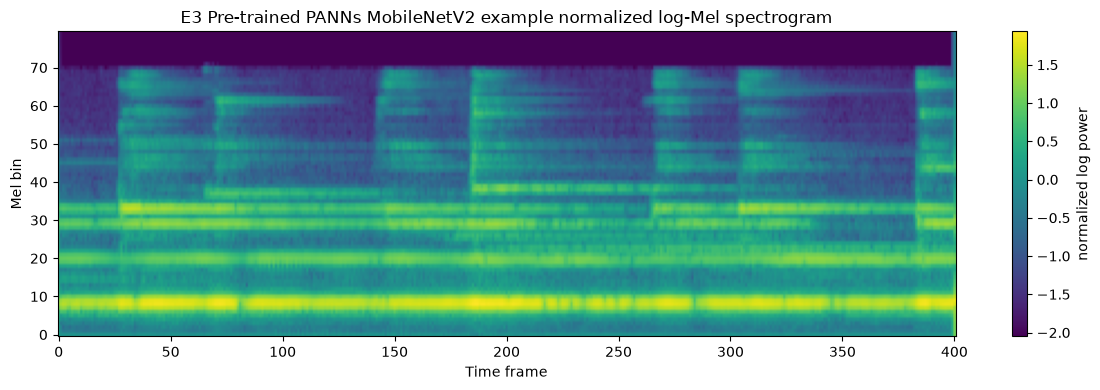

In [11]:
# 10. Visual sanity check for the GPU input representation

sample_row=train_run_df.iloc[0]

sample_path=audio_path_from_row(
    sample_row,
    PROJECT_ROOT
)

sample_wave=cpu_prepare_waveform(
    sample_path,
    sample_rate=SAMPLE_RATE,
    segment_seconds=SEGMENT_SECONDS,
    training=False
)

sample_batch=sample_wave.unsqueeze(0).to(
    DEVICE,
    non_blocking=True
)

with torch.no_grad():
    sample_logmel=gpu_logmel(
        sample_batch
    )

sample_logmel=normalize_log_mel(
    sample_logmel,
    MEL_MEAN,
    MEL_STD
)

sample_logmel=sample_logmel[0].cpu().numpy()

print("Audio:",sample_path.name)
print("Type:",sample_row["type"])
print("Label:",sample_row["label"])
print("Generator:",sample_row["generator"])
print("Waveform shape:",sample_wave.shape)
print("Log-Mel shape:",sample_logmel.shape)

plt.figure(figsize=(12,4))
plt.imshow(
    sample_logmel,
    origin="lower",
    aspect="auto"
)
plt.title("E3 Pre-trained PANNs MobileNetV2 example normalized log-Mel spectrogram")
plt.xlabel("Time frame")
plt.ylabel("Mel bin")
plt.colorbar(label="normalized log power")
plt.tight_layout()
plt.show()


In [12]:
# 11. Build the training and development DataLoaders

train_loader=make_waveform_loader(train_run_df,True)

dev_loader=make_waveform_loader(dev_run_df,False)

print("Training batches:",len(train_loader))
print("Development batches:",len(dev_loader))

Training batches: 1875
Development batches: 705


In [13]:
# 12. Build an AudioSet-pretrained PANNs MobileNetV2 with a binary classifier

# PANNs checkpoint reference:
# https://zenodo.org/records/3987831/files/MobileNetV2_mAP=0.383.pth?download=1


def conv_bn(inp, oup, stride):
    # Matches the upstream PANNs MobileNetV2 block (including ReLU6).
    return nn.Sequential(
        nn.Conv2d(inp, oup, 3, 1, 1, bias=False),
        nn.AvgPool2d(stride),
        nn.BatchNorm2d(oup),
        nn.ReLU6(inplace=True),
    )


def conv_1x1_bn(inp, oup):
    # Matches the upstream PANNs MobileNetV2 final 1x1 block.
    return nn.Sequential(
        nn.Conv2d(inp, oup, 1, 1, 0, bias=False),
        nn.BatchNorm2d(oup),
        nn.ReLU6(inplace=True),
    )


class InvertedResidual(nn.Module):
    def __init__(self, inp, oup, stride, expand_ratio):
        super().__init__()
        if stride not in [1, 2]:
            raise ValueError(f"Unsupported stride: {stride}")
        hidden_dim = round(inp * expand_ratio)
        self.use_res_connect = stride == 1 and inp == oup

        if expand_ratio == 1:
            layers = [
                nn.Conv2d(hidden_dim, hidden_dim, 3, 1, 1, groups=hidden_dim, bias=False),
                nn.AvgPool2d(stride),
                nn.BatchNorm2d(hidden_dim),
                nn.ReLU6(inplace=True),
                nn.Conv2d(hidden_dim, oup, 1, 1, 0, bias=False),
                nn.BatchNorm2d(oup),
            ]
        else:
            layers = [
                nn.Conv2d(inp, hidden_dim, 1, 1, 0, bias=False),
                nn.BatchNorm2d(hidden_dim),
                nn.ReLU6(inplace=True),
                nn.Conv2d(hidden_dim, hidden_dim, 3, 1, 1, groups=hidden_dim, bias=False),
                nn.AvgPool2d(stride),
                nn.BatchNorm2d(hidden_dim),
                nn.ReLU6(inplace=True),
                nn.Conv2d(hidden_dim, oup, 1, 1, 0, bias=False),
                nn.BatchNorm2d(oup),
            ]
        self.conv = nn.Sequential(*layers)

    def forward(self, x):
        if self.use_res_connect:
            return x + self.conv(x)
        return self.conv(x)


class PANNsMobileNetV2Audio(nn.Module):
    """PANNs MobileNetV2 feature extractor adapted to an 80-bin frontend.

    Expected input layout is [batch, 1, time, mel]. The convolutional feature
    stack and fc1 use the pretrained checkpoint. bn0 is freshly initialized
    because this experiment has 80 mel bins while the checkpoint uses 64. The
    original 527-class fc_audioset head is replaced by a binary classifier.
    """

    def __init__(self, pretrained_path=None, num_classes=2, dropout=0.2, auto_download=True):
        super().__init__()
        self.num_classes = num_classes
        self.dropout_rate = dropout

        inverted_residual_setting = [
            [1, 16, 1, 1],
            [6, 24, 2, 2],
            [6, 32, 3, 2],
            [6, 64, 4, 2],
            [6, 96, 3, 2],
            [6, 160, 3, 1],
            [6, 320, 1, 1],
        ]

        input_channel = 32
        features = [conv_bn(1, input_channel, 2)]
        for t, c, n, stride in inverted_residual_setting:
            output_channel = c
            for block_index in range(n):
                block_stride = stride if block_index == 0 else 1
                features.append(InvertedResidual(input_channel, output_channel, block_stride, expand_ratio=t))
                input_channel = output_channel
        features.append(conv_1x1_bn(input_channel, 1280))
        self.features = nn.Sequential(*features)

        # Upstream PANNs uses BatchNorm2d(64). Adapt its channel count to 80 mel bins.
        # This layer is deliberately fresh because the checkpoint tensor is shape-incompatible.
        self.bn0 = nn.BatchNorm2d(N_MELS)
        self.fc1 = nn.Linear(1280, 1024, bias=True)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(1024, num_classes, bias=True)
        self.pretrained_load_report = {
            "loaded_feature_tensors": 0,
            "expected_feature_tensors": 0,
            "loaded_fc1_tensors": 0,
            "expected_fc1_tensors": 0,
            "checkpoint_sha256": None,
        }

        if pretrained_path is not None:
            self.load_pretrained(pretrained_path, auto_download=auto_download)

    @staticmethod
    def _extract_state_dict(checkpoint):
        if not isinstance(checkpoint, dict):
            raise ValueError("The pretrained checkpoint is not a dictionary.")
        if isinstance(checkpoint.get("model"), dict):
            state_dict = checkpoint["model"]
        elif isinstance(checkpoint.get("state_dict"), dict):
            state_dict = checkpoint["state_dict"]
        else:
            state_dict = checkpoint
        # Handle DataParallel checkpoints without hiding other key mismatches.
        normalized = {}
        for key, value in state_dict.items():
            if not torch.is_tensor(value):
                continue
            key = key.removeprefix("module.")
            normalized[key] = value
        if not normalized:
            raise ValueError("No tensor state_dict entries were found in the pretrained checkpoint.")
        return normalized

    def load_pretrained(self, pretrained_path, auto_download=True):
        pretrained_path = Path(pretrained_path)
        pretrained_url = "https://zenodo.org/records/3987831/files/MobileNetV2_mAP%3D0.383.pth?download=1"

        if not pretrained_path.is_file() and auto_download:
            pretrained_path.parent.mkdir(parents=True, exist_ok=True)
            temporary_path = pretrained_path.with_suffix(pretrained_path.suffix + ".download")
            print(f"Downloading PANNs MobileNetV2 weights from Zenodo to {pretrained_path}...")
            try:
                request = urllib.request.Request(
                    pretrained_url,
                    headers={"User-Agent": "Mozilla/5.0 (compatible; ATADD-E3/1.0)"},
                )
                with urllib.request.urlopen(request, timeout=60) as response, open(temporary_path, "wb") as output_file:
                    while True:
                        chunk = response.read(1024 * 1024)
                        if not chunk:
                            break
                        output_file.write(chunk)
                if not temporary_path.is_file() or temporary_path.stat().st_size < 1024:
                    raise RuntimeError("Downloaded checkpoint is empty or unexpectedly small.")
                # Parse before replacing the target file so failed downloads are not left as checkpoints.
                torch.load(temporary_path, map_location="cpu", weights_only=False)
                temporary_path.replace(pretrained_path)
            except Exception as exc:
                if temporary_path.exists():
                    temporary_path.unlink()
                raise RuntimeError(
                    f"Could not download/validate the PANNs checkpoint. Download it manually from {pretrained_url} "
                    f"and place it at {pretrained_path}. Original error: {exc}"
                ) from exc

        if not pretrained_path.is_file():
            raise FileNotFoundError(
                f"PANNs pretrained checkpoint not found at {pretrained_path}. "
                f"Download it from {pretrained_url}."
            )

        checkpoint_bytes = pretrained_path.read_bytes()
        checkpoint_md5 = hashlib.md5(checkpoint_bytes).hexdigest()
        expected_md5 = "838421a9262cce976aa247946d6e2983"  # Official Zenodo MobileNetV2_mAP=0.383.pth
        if checkpoint_md5 != expected_md5:
            raise RuntimeError(
                "The PANNs MobileNetV2 checkpoint checksum does not match the official AudioSet release. "
                f"Expected MD5 {expected_md5}, got {checkpoint_md5}. Remove or replace {pretrained_path}."
            )
        checkpoint_hash = hashlib.sha256(checkpoint_bytes).hexdigest()
        checkpoint = torch.load(pretrained_path, map_location="cpu", weights_only=False)
        state_dict = self._extract_state_dict(checkpoint)
        model_dict = self.state_dict()
        compatible = {
            key: value for key, value in state_dict.items()
            if key in model_dict
            and model_dict[key].shape == value.shape
            and not key.startswith("bn0.")
        }

        expected_feature_keys = {key for key in model_dict if key.startswith("features.")}
        expected_fc1_keys = {key for key in model_dict if key.startswith("fc1.")}
        loaded_feature_keys = expected_feature_keys & set(compatible)
        loaded_fc1_keys = expected_fc1_keys & set(compatible)
        missing_feature_keys = sorted(expected_feature_keys - loaded_feature_keys)
        missing_fc1_keys = sorted(expected_fc1_keys - loaded_fc1_keys)
        if missing_feature_keys or missing_fc1_keys:
            raise RuntimeError(
                "The checkpoint did not load all required pretrained PANNs tensors. "
                f"Missing feature tensors: {missing_feature_keys[:12]}; "
                f"missing fc1 tensors: {missing_fc1_keys}. Check the checkpoint/model version."
            )

        model_dict.update(compatible)
        self.load_state_dict(model_dict)
        self.pretrained_load_report = {
            "loaded_feature_tensors": len(loaded_feature_keys),
            "expected_feature_tensors": len(expected_feature_keys),
            "loaded_fc1_tensors": len(loaded_fc1_keys),
            "expected_fc1_tensors": len(expected_fc1_keys),
            "checkpoint_sha256": checkpoint_hash,
            "checkpoint_md5": checkpoint_md5,
            "expected_official_checkpoint_md5": expected_md5,
            "fresh_layers": ["bn0 (80 mel bins; checkpoint has 64)", "classifier (binary head)"],
        }
        print(
            "Loaded pretrained PANNs tensors: "
            f"features {len(loaded_feature_keys)}/{len(expected_feature_keys)}, "
            f"fc1 {len(loaded_fc1_keys)}/{len(expected_fc1_keys)}."
        )
        print("Freshly initialized adaptation layers: bn0(80), binary classifier(1024→2).")
        print("Pretrained checkpoint SHA-256:", checkpoint_hash)

    def forward(self, x, return_features=False):
        # Required time-major PANNs input layout: [B, 1, T, M].
        if x.ndim != 4 or x.shape[1] != 1 or x.shape[-1] != N_MELS:
            raise ValueError(
                f"Expected PANNs input [B, 1, time, {N_MELS} mel bins], got {tuple(x.shape)}"
            )

        # Upstream PANNs applies bn0 in mel-channel layout. The 80-bin layer is adapted/fresh.
        x = self.bn0(x.transpose(1, 3)).transpose(1, 3).contiguous()
        feat_map = self.features(x)  # [B, 1280, reduced_time, reduced_mel]

        # Match upstream PANNs pooling order: average over mel, then temporal max + temporal mean.
        temporal_features = torch.mean(feat_map, dim=3)  # [B, 1280, reduced_time]
        temporal_max = torch.max(temporal_features, dim=2).values
        temporal_mean = torch.mean(temporal_features, dim=2)
        pooled = temporal_max + temporal_mean  # [B, 1280]

        embedding = F.relu_(self.fc1(pooled))
        embedding_for_classifier = self.dropout(embedding)
        logits = self.classifier(embedding_for_classifier)
        if return_features:
            return logits, feat_map
        return logits

    @property
    def num_parameters(self):
        return sum(parameter.numel() for parameter in self.parameters())


model = PANNsMobileNetV2Audio(
    pretrained_path=PRETRAINED_WEIGHTS_PATH,
    num_classes=2,
    dropout=CLASSIFIER_DROPOUT,
).to(DEVICE)

total_params = sum(parameter.numel() for parameter in model.parameters())
trainable_params = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

print("=" * 64)
print("E3 Architecture: PANNs MobileNetV2 AudioSet-pretrained transfer baseline")
print("Pretrained source:", PRETRAINED_WEIGHTS_PATH)
print("Classification head: 1024 → 2 (Real vs Fake)")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("=" * 64)


Loaded pretrained PANNs tensors: features 312/312, fc1 2/2.
Freshly initialized adaptation layers: bn0(80), binary classifier(1024→2).
Pretrained checkpoint SHA-256: 22437af9eb5ed1854b5ad285b4a17d5fc566f1a3b23df40db5541f5705ca340f
E3 Architecture: PANNs MobileNetV2 AudioSet-pretrained transfer baseline
Pretrained source: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/pretrained/panns/MobileNetV2_mAP=0.383.pth
Classification head: 1024 → 2 (Real vs Fake)
Total parameters: 3,537,250
Trainable parameters: 3,537,250


# 13. Loss function and optimizer

E3 uses class-weighted cross-entropy with weights computed from the actual training split counts (not hard-coded expected counts). AdamW uses learning rate `3e-4` and weight decay `1e-4`. `ReduceLROnPlateau` adjusts the learning rate using development Macro-F1.

The development set is used for checkpoint selection and threshold calibration. The evaluation set is held out for final generalization reporting.


In [14]:
# 13. Loss and optimizer (Class-Weighted Cross-Entropy)

# Compute inverse-frequency class weights from the actual training subset.
class_counts = train_run_df["label"].map(LABEL_MAP).value_counts().reindex([0, 1], fill_value=0).sort_index()
total_samples = len(train_run_df)
if (class_counts == 0).any():
    raise ValueError(f"Both classes must be present in train_run_df; counts={class_counts.to_dict()}")

# Balanced weight formula: w_c = N / (C * N_c), with C=2.
class_weights = total_samples / (2.0 * class_counts.to_numpy(dtype=np.float32))
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

optimizer = torch.optim.AdamW(
    [
        {"params": model.features.parameters(), "lr": BACKBONE_LEARNING_RATE},
        {"params": model.fc1.parameters(), "lr": FC1_LEARNING_RATE},
        {"params": model.bn0.parameters(), "lr": LEARNING_RATE},
        {"params": model.classifier.parameters(), "lr": LEARNING_RATE},
    ],
    weight_decay=WEIGHT_DECAY
)

# Reduce each parameter group's LR on a development Macro-F1 plateau.
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

print(f"Training Class Counts (0=Real, 1=Fake): {class_counts.to_dict()}")
print(f"Class Weights (Real, Fake)            : {class_weights}")
print(f"Loss Function                          : CrossEntropyLoss(weight={class_weights_tensor.cpu().numpy()})")
print(f"Learning rates (backbone / fc1 / bn0 / classifier): {BACKBONE_LEARNING_RATE:.2e} / {FC1_LEARNING_RATE:.2e} / {LEARNING_RATE:.2e} / {LEARNING_RATE:.2e}")
print(f"Freeze pretrained BatchNorm running stats: {FREEZE_PRETRAINED_BN_STATS}")

Training Class Counts (0=Real, 1=Fake): {0: 16000, 1: 44000}
Class Weights (Real, Fake)            : [1.875     0.6818182]
Loss Function                          : CrossEntropyLoss(weight=[1.875     0.6818182])
Learning rates (backbone / fc1 / bn0 / classifier): 1.00e-05 / 5.00e-05 / 3.00e-04 / 3.00e-04
Freeze pretrained BatchNorm running stats: True


# 14. Evaluation metrics

The main E3 metrics are:

### Macro-F1

Macro-F1 calculates F1 separately for real and fake classes and averages them, preventing the majority fake class from dominating.

### AUROC

AUROC measures threshold-independent discrimination between fake and real clips.

### EER

Equal Error Rate is calculated from the ROC curve where false-positive and false-negative rates are equal.


In [15]:
# 14. Evaluation metrics (compute_eer, calculate_metrics, waveform_batch_to_features, run_evaluation)

def compute_eer(y_true, scores):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    if len(np.unique(y_true)) < 2:
        return float("nan"), float("nan")
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    fnr = 1.0 - tpr
    index = np.nanargmin(np.abs(fpr - fnr))
    eer = float((fpr[index] + fnr[index]) / 2.0)
    threshold = float(thresholds[index])
    return eer, threshold

def calculate_metrics(y_true, scores, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores).astype(float)
    if len(y_true) == 0:
        raise ValueError("Cannot calculate metrics on an empty dataset.")
    predictions = (scores >= threshold).astype(int)
    metrics = {
        "macro_f1": float(f1_score(y_true, predictions, average="macro", zero_division=0)),
        "accuracy": float(accuracy_score(y_true, predictions)),
        "auroc": float("nan")
    }
    if len(np.unique(y_true)) == 2:
        metrics["auroc"] = float(roc_auc_score(y_true, scores))
    eer, eer_threshold = compute_eer(y_true, scores)
    metrics["eer"] = eer
    metrics["eer_threshold"] = eer_threshold
    return metrics, predictions

@torch.no_grad()
def waveform_batch_to_features(waveforms):
    waveforms = waveforms.to(DEVICE, non_blocking=True)
    log_mel = gpu_logmel(waveforms)
    log_mel = normalize_log_mel(log_mel, MEL_MEAN, MEL_STD)

    # GPULogMel returns [batch, mel, time]. Original PANNs MobileNetV2
    # expects [batch, channel, time, mel], so transpose axes here.
    if log_mel.ndim != 3:
        raise ValueError(f"Expected log-Mel shape [B, M, T], got {tuple(log_mel.shape)}")
    if log_mel.shape[1] != N_MELS:
        raise ValueError(f"Expected {N_MELS} mel bins on axis 1, got shape {tuple(log_mel.shape)}")
    return log_mel.transpose(1, 2).contiguous().unsqueeze(1)

@torch.no_grad()
def run_evaluation(model, loader, criterion=None, description="Evaluating"):
    model.eval()
    total_loss = 0.0
    total_items = 0
    all_labels = []
    all_scores = []
    all_file_ids = []
    for waveforms, y, file_ids in tqdm(loader, desc=description, leave=False):
        y = y.to(DEVICE, non_blocking=True)
        x = waveform_batch_to_features(waveforms)
        with autocast_context():
            logits = model(x)
            if criterion is not None:
                loss = criterion(logits, y)
        if criterion is not None:
            total_loss += float(loss.item()) * x.size(0)
        scores = torch.softmax(logits.float(), dim=1)[:, 1]
        all_labels.extend(y.cpu().numpy().tolist())
        all_scores.extend(scores.float().cpu().numpy().tolist())
        all_file_ids.extend(list(file_ids))
        total_items += x.size(0)
    avg_loss = total_loss / max(total_items, 1)
    metrics, predictions = calculate_metrics(all_labels, all_scores)
    metrics["loss"] = avg_loss
    return metrics, np.asarray(all_labels), np.asarray(all_scores), predictions, all_file_ids

## GPU training and GPU feature extraction

CPU DataLoader workers handle audio decoding, resampling and crop/repeat-padding. Batched STFT, Mel extraction, log compression and normalization run on the GPU when CUDA is available.

In [16]:
# 15. Mixed-precision training setup

amp_enabled=DEVICE.type=="cuda"

scaler=torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

def autocast_context():
    return torch.amp.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16,
        enabled=amp_enabled
    )

# 16. Training loop

The model is trained on the training partition and evaluated on the development partition after every epoch.

The best checkpoint is selected using **development Macro-F1**.

Training runs for the full 25 epochs without early stopping, preserving the best checkpoint achieved on development Macro-F1.

The evaluation partition is not used during model selection.

In [17]:
# 16. Train one epoch with gradient clipping

def set_conservative_train_mode(model):
    """Train the model while preserving pretrained feature BatchNorm running stats.

    model.bn0 is a newly initialized 80-bin adaptation layer, so it remains in
    training mode. BatchNorm layers inside the pretrained `features` stack use
    their stored AudioSet running statistics; their affine weights remain
    trainable with the low backbone learning rate.
    """
    model.train()
    if FREEZE_PRETRAINED_BN_STATS:
        for module in model.features.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()


def train_one_epoch(model, loader):
    set_conservative_train_mode(model)
    running_loss = 0.0
    correct = 0
    total_items = 0
    grad_norms = []

    progress = tqdm(loader, desc="Training", leave=False)

    for waveforms, y, _ in progress:
        y = y.to(DEVICE, non_blocking=True)
        x = waveform_batch_to_features(waveforms)

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits = model(x)
            loss = criterion(logits, y)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)                                              # 1. unscale first
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)  # 2. then clip
        if torch.isfinite(gn):
            grad_norms.append(float(gn))
        scaler.step(optimizer)                                                  # 3. step skips inf/nan automatically
        scaler.update()

        predictions = torch.argmax(logits, dim=1)
        correct += (predictions == y).sum().item()
        running_loss += float(loss.item()) * x.size(0)
        total_items += x.size(0)

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = running_loss / max(total_items, 1)
    train_accuracy = correct / max(total_items, 1)
    gn_med = float(np.median(grad_norms)) if grad_norms else 0.0
    gn_p99 = float(np.percentile(grad_norms, 99)) if grad_norms else 0.0

    return train_loss, train_accuracy, gn_med, gn_p99

In [18]:
# 17. Train E3 PANNs MobileNetV2 with Conservative Fine-Tuning (25 Epochs, Multi-Seed Protocol)

history = []
best_dev_f1 = -np.inf
best_epoch = -1
epochs_without_improvement = 0

best_checkpoint_path = CHECKPOINT_DIR / f"E3_PANNs_MobileNetV2_ATADD_best_{SEED_TAG}.pt"
history_path = EXPERIMENT_DIR / f"E3_ATADD_training_history_{SEED_TAG}.csv"

print(f"Starting E3 Pre-trained PANNs MobileNetV2 ({SEED_TAG}, seed={SEED}) training for {EPOCHS} epochs (Early stopping disabled, Max Grad Norm: {MAX_GRAD_NORM})...")

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    train_loss, train_accuracy, gn_med, gn_p99 = train_one_epoch(model, train_loader)
    dev_metrics, dev_y, dev_scores, dev_preds, dev_ids = run_evaluation(model, dev_loader, criterion)

    # Step scheduler based on Dev Macro-F1
    scheduler.step(dev_metrics["macro_f1"])
    epoch_time = time.time() - start_time

    row = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "train_accuracy": float(train_accuracy),
        "grad_norm_median": float(gn_med),
        "grad_norm_p99": float(gn_p99),
        "dev_loss": float(dev_metrics["loss"]),
        "dev_accuracy": float(dev_metrics["accuracy"]),
        "dev_macro_f1": float(dev_metrics["macro_f1"]),
        "dev_auroc": float(dev_metrics["auroc"]),
        "dev_eer": float(dev_metrics["eer"]),
        "lr": float(optimizer.param_groups[3]["lr"]),  # classifier LR for backwards-compatible plotting
        "lr_backbone": float(optimizer.param_groups[0]["lr"]),
        "lr_fc1": float(optimizer.param_groups[1]["lr"]),
        "lr_bn0": float(optimizer.param_groups[2]["lr"]),
        "lr_classifier": float(optimizer.param_groups[3]["lr"]),
        "epoch_seconds": float(epoch_time),
        "seed_tag": SEED_TAG,
        "seed": SEED
    }
    history.append(row)

    history_df = pd.DataFrame(history)
    history_df.to_csv(history_path, index=False)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} [{epoch_time:.1f}s] | "
        f"Train Loss: {train_loss:.4f} Acc: {train_accuracy:.4f} | "
        f"GN(med/p99): {gn_med:.2f}/{gn_p99:.2f} | "
        f"Dev Loss: {dev_metrics['loss']:.4f} Acc: {dev_metrics['accuracy']:.4f} "
        f"F1: {dev_metrics['macro_f1']:.4f} AUROC: {dev_metrics['auroc']:.4f} EER: {dev_metrics['eer']*100:.2f}% | "
        f"LR(bb/fc1/head): {optimizer.param_groups[0]['lr']:.1e}/"
        f"{optimizer.param_groups[1]['lr']:.1e}/{optimizer.param_groups[3]['lr']:.1e}"
    )

    if dev_metrics["macro_f1"] > best_dev_f1:
        best_dev_f1 = dev_metrics["macro_f1"]
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(
            {
                "experiment": f"E3_ATADD_Reworked_{SEED_TAG}",
                "experiment_version": EXPERIMENT_VERSION,
                "input_preprocessing_version": INPUT_PREPROCESSING_VERSION,
                "model_name": "PANNs-MobileNetV2-AudioSet",
                "model_config": {
                    "num_classes": 2,
                    "pretrained_weights": str(PRETRAINED_WEIGHTS_PATH),
                    "classifier_dropout": CLASSIFIER_DROPOUT,
                "input_layout": "B,1,time,mel",
                "pooling": "mean over mel, then temporal max + temporal mean",
                "pretrained_load_report": model.pretrained_load_report
                },
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "dev_metrics": dev_metrics,
                "seed_tag": SEED_TAG,
                "seed": SEED,
                "max_grad_norm": MAX_GRAD_NORM,
                "learning_rates": {
                    "backbone": BACKBONE_LEARNING_RATE,
                    "fc1": FC1_LEARNING_RATE,
                    "bn0": LEARNING_RATE,
                    "classifier": LEARNING_RATE
                },
                "freeze_pretrained_bn_stats": FREEZE_PRETRAINED_BN_STATS,
                "class_weights": class_weights.tolist()
            },
            best_checkpoint_path
        )
        print(f"  -> Best Dev Macro-F1: {best_dev_f1:.6f} saved to {best_checkpoint_path.name}")
    else:
        epochs_without_improvement += 1
        print(f"  -> No improvement for {epochs_without_improvement} epoch(s)")

print(f"\nTraining complete! Best checkpoint: {best_checkpoint_path} (Epoch {best_epoch}, Dev Macro-F1: {best_dev_f1:.6f})")


Starting E3 Pre-trained PANNs MobileNetV2 (seed3, seed=2024) training for 25 epochs (Early stopping disabled, Max Grad Norm: 5.0)...


Epoch 01/25 [146.7s] | Train Loss: 0.4289 Acc: 0.7913 | GN(med/p99): 5.84/18.16 | Dev Loss: 0.7375 Acc: 0.6648 F1: 0.6494 AUROC: 0.7732 EER: 29.59% | LR(bb/fc1/head): 1.0e-05/5.0e-05/3.0e-04
  -> Best Dev Macro-F1: 0.649356 saved to E3_PANNs_MobileNetV2_ATADD_best_seed3.pt


Epoch 02/25 [143.9s] | Train Loss: 0.2921 Acc: 0.8728 | GN(med/p99): 10.67/39.29 | Dev Loss: 0.5993 Acc: 0.7395 F1: 0.7058 AUROC: 0.8047 EER: 27.30% | LR(bb/fc1/head): 1.0e-05/5.0e-05/3.0e-04
  -> Best Dev Macro-F1: 0.705784 saved to E3_PANNs_MobileNetV2_ATADD_best_seed3.pt


Epoch 03/25 [146.0s] | Train Loss: 0.2376 Acc: 0.9028 | GN(med/p99): 11.96/61.00 | Dev Loss: 0.5973 Acc: 0.7597 F1: 0.7290 AUROC: 0.8366 EER: 24.80% | LR(bb/fc1/head): 1.0e-05/5.0e-05/3.0e-04
  -> Best Dev Macro-F1: 0.728962 saved to E3_PANNs_MobileNetV2_ATADD_best_seed3.pt


Epoch 04/25 [145.5s] | Train Loss: 0.1999 Acc: 0.9217 | GN(med/p99): 12.69/60.20 | Dev Loss: 0.6963 Acc: 0.7543 F1: 0.7273 AUROC: 0.8414 EER: 24.46% | LR(bb/fc1/head): 1.0e-05/5.0e-05/3.0e-04
  -> No improvement for 1 epoch(s)


...

Epoch 21/25 [144.1s] | Train Loss: 0.0690 Acc: 0.9781 | GN(med/p99): 9.68/87.21 | Dev Loss: 1.0099 Acc: 0.7701 F1: 0.7508 AUROC: 0.8815 EER: 20.51% | LR(bb/fc1/head): 5.0e-06/2.5e-05/1.5e-04
  -> No improvement for 3 epoch(s)


Epoch 22/25 [144.2s] | Train Loss: 0.0669 Acc: 0.9785 | GN(med/p99): 9.83/86.26 | Dev Loss: 1.0886 Acc: 0.7622 F1: 0.7429 AUROC: 0.8751 EER: 20.90% | LR(bb/fc1/head): 2.5e-06/1.3e-05/7.5e-05
  -> No improvement for 4 epoch(s)


Epoch 23/25 [144.3s] | Train Loss: 0.0612 Acc: 0.9811 | GN(med/p99): 8.03/83.03 | Dev Loss: 1.0557 Acc: 0.7704 F1: 0.7504 AUROC: 0.8798 EER: 20.58% | LR(bb/fc1/head): 2.5e-06/1.3e-05/7.5e-05
  -> No improvement for 5 epoch(s)


Epoch 24/25 [149.5s] | Train Loss: 0.0626 Acc: 0.9804 | GN(med/p99): 8.85/79.36 | Dev Loss: 1.1363 Acc: 0.7555 F1: 0.7400 AUROC: 0.8883 EER: 19.76% | LR(bb/fc1/head): 2.5e-06/1.3e-05/7.5e-05
  -> No improvement for 6 epoch(s)


Epoch 25/25 [143.4s] | Train Loss: 0.0613 Acc: 0.9808 | GN(med/p99): 8.60/84.49 | Dev Loss: 1.1038 Acc: 0.7631 F1: 0.7447 AUROC: 0.8799 EER: 20.55% | LR(bb/fc1/head): 2.5e-06/1.3e-05/7.5e-05
  -> No improvement for 7 epoch(s)

Training complete! Best checkpoint: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/checkpoints/reworked/E3_conservative_finetune/E3_PANNs_MobileNetV2_ATADD_best_seed3.pt (Epoch 18, Dev Macro-F1: 0.755882)


## Training curves

The training curves provide a quick way to identify:

- underfitting
- overfitting
- unstable optimization
- whether the development performance has stopped improving

These plots are saved under `results/figures/` for the project record.

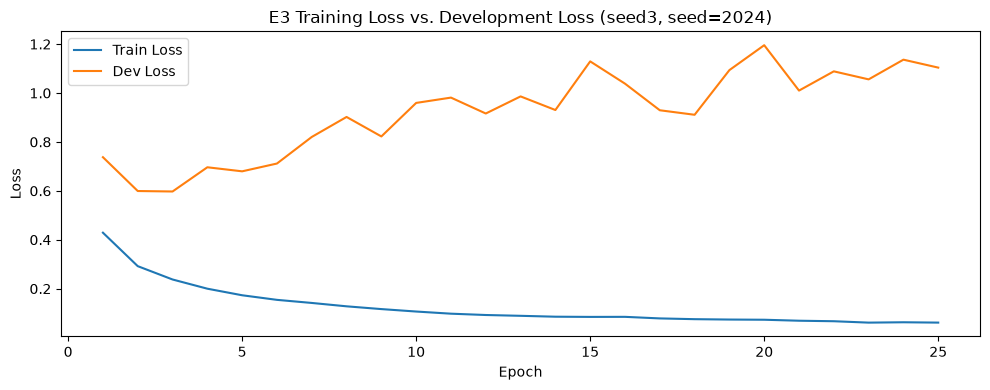

Saved training curves to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/reworked/E3_conservative_finetune/E3_ATADD_training_curves_seed3.png


In [19]:
# 18. Plot and save training curves

plt.figure(figsize=(10, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train Loss")
plt.plot(history_df["epoch"], history_df["dev_loss"], label="Dev Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"E3 Training Loss vs. Development Loss ({SEED_TAG}, seed={SEED})")
plt.legend()
plt.tight_layout()

curves_path = RESULT_FIGURE_DIR / f"E3_ATADD_training_curves_{SEED_TAG}.png"
plt.savefig(curves_path, dpi=200)
plt.show()

print("Saved training curves to:", curves_path)


# 19. Final development evaluation

After training, we reload the checkpoint with the best development Macro-F1.

All reported development metrics below therefore correspond to the selected E3 checkpoint rather than simply the final training epoch.


In [20]:
checkpoint=torch.load(best_checkpoint_path,map_location=DEVICE,weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])

print(f"Loaded checkpoint for {SEED_TAG} from epoch:",checkpoint["epoch"])
print(f"Best development Macro-F1 ({SEED_TAG}):",checkpoint["dev_metrics"]["macro_f1"])

Loaded checkpoint for seed3 from epoch: 18
Best development Macro-F1 (seed3): 0.7558818495344727


## Development-set results

These are the metrics used to assess how well the pre-trained E3 model adapted to the real/fake audio classification task.

The development predictions are also saved for downstream error analysis.


In [21]:
# 20. Final development-set evaluation & Decision-Threshold Calibration

val_metrics_05, val_y, val_scores, val_preds_05, val_ids = run_evaluation(model, dev_loader, criterion)

# Sweep decision thresholds on the validation set to find optimal threshold theta*
# Match E1/E2 calibration grid exactly: 99 candidates from 0.01 through 0.99.
candidate_thresholds = np.linspace(0.01, 0.99, 99)
sweep_records = []
best_dev_thresh = 0.50
best_dev_macro_f1 = -1.0

for t in candidate_thresholds:
    preds_t = (val_scores >= t).astype(int)
    f1_t = f1_score(val_y, preds_t, average="macro", zero_division=0)
    acc_t = accuracy_score(val_y, preds_t)
    bacc_t = balanced_accuracy_score(val_y, preds_t)
    if f1_t > best_dev_macro_f1:
        best_dev_macro_f1 = f1_t
        best_dev_thresh = float(t)
    sweep_records.append({
        "threshold": float(t),
        "macro_f1": float(f1_t),
        "accuracy": float(acc_t),
        "balanced_accuracy": float(bacc_t)
    })

dev_sweep_df = pd.DataFrame(sweep_records)
dev_sweep_path = EXPERIMENT_DIR / f"E3_ATADD_dev_threshold_sweep_{SEED_TAG}.csv"
dev_sweep_df.to_csv(dev_sweep_path, index=False)

# Compute metrics at the calibrated threshold
val_metrics_opt, val_preds_opt = calculate_metrics(val_y, val_scores, threshold=best_dev_thresh)
val_metrics_opt["loss"] = val_metrics_05["loss"]

print(f"=== E3 VALIDATION RESULTS ({SEED_TAG}) ===")
print(f"Fixed Default Threshold (theta = 0.50):")
print(f"  Macro-F1          : {val_metrics_05['macro_f1']:.6f}")
print(f"  Accuracy          : {val_metrics_05['accuracy']:.6f}")
print(f"  AUROC             : {val_metrics_05['auroc']:.6f}")
print(f"  EER               : {val_metrics_05['eer']*100:.2f}% (threshold={val_metrics_05['eer_threshold']:.4f})")
print(f"\nDev-Calibrated Threshold (theta* = {best_dev_thresh:.4f}):")
print(f"  Calibrated Macro-F1: {val_metrics_opt['macro_f1']:.6f} (Delta: {val_metrics_opt['macro_f1'] - val_metrics_05['macro_f1']:+.6f})")
print(f"  Calibrated Accuracy: {val_metrics_opt['accuracy']:.6f}")

val_metrics_all = {
    "fixed_0.5": val_metrics_05,
    "calibrated_dev": val_metrics_opt,
    "optimal_dev_threshold": best_dev_thresh
}

val_metrics_path = EXPERIMENT_DIR / f"E3_ATADD_validation_metrics_{SEED_TAG}.json"
with open(val_metrics_path, "w", encoding="utf-8") as f:
    json.dump(val_metrics_all, f, indent=2)

print("Saved validation metrics to:", val_metrics_path)


=== E3 VALIDATION RESULTS (seed3) ===
Fixed Default Threshold (theta = 0.50):
  Macro-F1          : 0.755882
  Accuracy          : 0.778088
  AUROC             : 0.877422
  EER               : 20.88% (threshold=0.3172)

Dev-Calibrated Threshold (theta* = 0.0500):
  Calibrated Macro-F1: 0.779394 (Delta: +0.023513)
  Calibrated Accuracy: 0.817670
Saved validation metrics to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune/E3_ATADD_validation_metrics_seed3.json


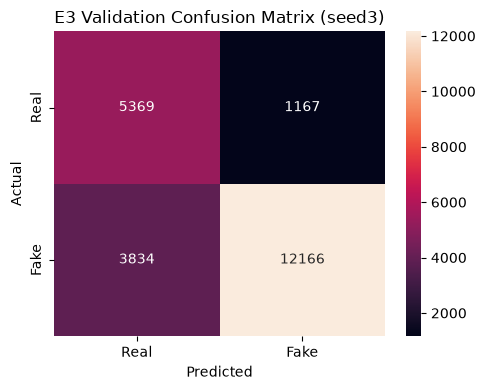

Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/reworked/E3_conservative_finetune/E3_ATADD_validation_confusion_matrix_seed3.png


In [22]:
# 21. Validation confusion matrix

cm = confusion_matrix(val_y, val_preds_05)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Real", "Fake"],
    yticklabels=["Real", "Fake"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"E3 Validation Confusion Matrix ({SEED_TAG})")
plt.tight_layout()

val_cm_path = RESULT_FIGURE_DIR / f"E3_ATADD_validation_confusion_matrix_{SEED_TAG}.png"
plt.savefig(val_cm_path, dpi=200)
plt.show()

print("Saved:", val_cm_path)


## Save development predictions

Saving the individual prediction scores is useful later when comparing E1 with E2/E3 or investigating difficult examples.

The file contains the model's fake score, predicted class and ground-truth label for each development recording.

In [23]:
# 22. Save validation predictions for later analysis

val_output = pd.DataFrame({
    "file_id": val_ids,
    "label": val_y,
    "spoof_score": val_scores,
    "prediction_05": (val_scores >= 0.5).astype(int),
    "prediction_opt": (val_scores >= best_dev_thresh).astype(int),
    "seed_tag": SEED_TAG,
    "seed": SEED
})

val_output_path = EXPERIMENT_DIR / f"E3_ATADD_val_predictions_{SEED_TAG}.csv"
val_output.to_csv(val_output_path, index=False)
print("Saved validation predictions to:", val_output_path)


Saved validation predictions to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune/E3_ATADD_val_predictions_seed3.csv


# 23. Official evaluation inference

The required evaluation manifest is evaluated only after the model checkpoint has been selected on development data. The actual sample count and generator coverage are read from the manifest and checked at runtime; they are not assumed from hard-coded numbers.


In [24]:
# 23. Prepare the required official evaluation DataLoader

eval_scores = np.asarray([])
eval_labels = np.asarray([])
eval_ids = []
eval_analysis = pd.DataFrame()

if eval_run_df.empty:
    raise ValueError("The evaluation subset is empty. Check EVAL_FRACTION and the evaluation manifest.")
if set(eval_run_df["label"].unique()) != {"real", "fake"}:
    raise ValueError(
        "The evaluation subset must contain both real and fake classes to report the configured metrics. "
        f"Found: {sorted(eval_run_df['label'].unique())}"
    )

eval_loader = make_waveform_loader(eval_run_df, False)
print(f"Evaluation loader ready: {len(eval_run_df):,} clips in {len(eval_loader):,} batches")


Evaluation loader ready: 44,289 clips in 1,385 batches


In [25]:
# 24. Run official evaluation inference (Dual Thresholds: Fixed 0.5 & Dev-Calibrated theta*)

if len(eval_run_df):
    model.eval()
    eval_scores = []
    eval_labels = []
    eval_ids = []

    with torch.no_grad():
        for waveforms, y, file_ids in tqdm(eval_loader, desc=f"Official evaluation ({SEED_TAG})"):
            y = y.to(DEVICE, non_blocking=True)
            x = waveform_batch_to_features(waveforms)
            with autocast_context():
                logits = model(x)
            scores = torch.softmax(logits.float(), dim=1)[:, 1]
            eval_scores.extend(scores.float().cpu().numpy().tolist())
            eval_labels.extend(y.cpu().numpy().tolist())
            eval_ids.extend(list(file_ids))

    eval_scores = np.asarray(eval_scores)
    eval_labels = np.asarray(eval_labels)

    expected_eval_ids = eval_run_df["file_id"].astype(str).tolist()
    if eval_ids != expected_eval_ids:
        raise RuntimeError(
            "Evaluation prediction order/IDs do not match the evaluation manifest order; "
            "refusing to generate per-type/per-generator analysis from misaligned rows."
        )
    if len(eval_scores) != len(eval_run_df) or len(eval_labels) != len(eval_run_df):
        raise RuntimeError(
            f"Evaluation produced {len(eval_scores)} scores for {len(eval_run_df)} manifest rows."
        )

    # Compute predictions at BOTH thresholds
    eval_predictions_05 = (eval_scores >= 0.5).astype(int)
    eval_predictions_opt = (eval_scores >= best_dev_thresh).astype(int)

    eval_output = pd.DataFrame({
        "file_id": eval_ids,
        "label": eval_labels,
        "spoof_score": eval_scores,
        "prediction": eval_predictions_05,        # Default 0.5
        "prediction_05": eval_predictions_05,     # Explicit 0.5
        "prediction_opt": eval_predictions_opt,   # Dev-selected theta*
        "seed_tag": SEED_TAG,
        "seed": SEED
    })

    eval_output_path = EXPERIMENT_DIR / f"E3_ATADD_eval_predictions_{SEED_TAG}.csv"
    eval_output.to_csv(eval_output_path, index=False)
    print("Saved evaluation predictions to:", eval_output_path)

    if len(np.unique(eval_labels)) == 2:
        eval_metrics_05, _ = calculate_metrics(eval_labels, eval_scores, threshold=0.5)
        eval_metrics_opt, _ = calculate_metrics(eval_labels, eval_scores, threshold=best_dev_thresh)

        print(f"\n=== OFFICIAL AT-ADD EVALUATION RESULTS ({SEED_TAG}) ===")
        print(f"--- 1. Default Threshold (theta = 0.50) ---")
        for k, v in eval_metrics_05.items():
            print(f"  {k:<16}: {v:.6f}")

        print(f"\n--- 2. Dev-Calibrated Threshold (theta* = {best_dev_thresh:.4f}) ---")
        for k, v in eval_metrics_opt.items():
            print(f"  {k:<16}: {v:.6f}")

        eval_comparison_summary = {
            "fixed_threshold_0.5": eval_metrics_05,
            "dev_calibrated_threshold": eval_metrics_opt,
            "calibrated_threshold_value": best_dev_thresh
        }

        eval_metrics_path = EXPERIMENT_DIR / f"E3_ATADD_eval_metrics_{SEED_TAG}.json"
        with open(eval_metrics_path, "w", encoding="utf-8") as f:
            json.dump(eval_comparison_summary, f, indent=2)
        print("Saved dual-threshold metrics to:", eval_metrics_path)
    else:
        print("\nEvaluation labels do not contain both classes.")
else:
    print("No evaluation manifest was found.")


Official evaluation (seed3): 100%|██████████| 1385/1385 [00:56<00:00, 24.45it/s]


Saved evaluation predictions to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune/E3_ATADD_eval_predictions_seed3.csv

=== OFFICIAL AT-ADD EVALUATION RESULTS (seed3) ===
--- 1. Default Threshold (theta = 0.50) ---
  macro_f1        : 0.672497
  accuracy        : 0.752670
  auroc           : 0.882491
  eer             : 0.196104
  eer_threshold   : 0.162779

--- 2. Dev-Calibrated Threshold (theta* = 0.0500) ---
  macro_f1        : 0.729738
  accuracy        : 0.833051
  auroc           : 0.882491
  eer             : 0.196104
  eer_threshold   : 0.162779
Saved dual-threshold metrics to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune/E3_ATADD_eval_metrics_seed3.json


DUAL-THRESHOLD GENERALIZATION AUDIT (seed3)
Thresholds: Default theta=0.50  vs.  Dev-Calibrated theta*=0.0500

[A] Per-Type Domain Breakdown (4 Domains)
----------------------------------------------------------------------


,Domain,Total Samples,Real Samples,Fake Samples,Macro-F1 (0.50),Macro-F1 (theta*),Delta F1,AUROC,EER (%)
0,Speech,27000,2000,25000,0.627565,0.688621,0.061056,0.898426,17.992000
1,Sound,6000,2000,4000,0.646112,0.689705,0.043593,0.788786,29.200000
2,Singing,6753,2000,4753,0.730478,0.769900,0.039422,0.861246,21.398506
3,Music,4536,536,4000,0.567389,0.655985,0.088596,0.812074,26.702052


Type-Averaged Macro-F1 at theta=0.50   : 0.642886
Type-Averaged Macro-F1 at theta*=0.05: 0.701053 (Delta: +0.058167)
Saved domain breakdown to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune/E3_ATADD_eval_type_results_seed3.csv

[B] Per-Generator Breakdown on 38 Unseen Fake Generators
----------------------------------------------------------------------


,Generator,Domain,Samples,Recall (0.50),Recall (theta*),Delta Recall,Mean Spoof Score
21,MeanAudio,sound,1000,0.047000,0.186000,0.139000,0.066699
2,BigVGAN,speech,1000,0.116000,0.269000,0.153000,0.131614
1,Auffusion,sound,1000,0.404000,0.603000,0.199000,0.411376
33,StyleTTS2,speech,1000,0.408000,0.641000,0.233000,0.407920
0,ACE-Step,music,1000,0.455000,0.699000,0.244000,0.457383
16,IndexTTS2,speech,1000,0.477000,0.718000,0.241000,0.483776
36,VEVO1.5,singing,1000,0.618000,0.775000,0.157000,0.606877
17,KNN-SVC,singing,1000,0.611000,0.795000,0.184000,0.599954
25,RVC-FSD,singing,753,0.698539,0.800797,0.102258,0.683490
22,Musictango,music,1000,0.609000,0.808000,0.199000,0.603174


Additional generators not shown: 23
Saved generator breakdown to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune/E3_ATADD_eval_generator_results_seed3.csv

[C] Real Audio: Seen vs. Unseen Source Breakdown
----------------------------------------------------------------------


,Source Category,Clips,Real Acc (0.50),False Alarm (0.50),Real Acc (theta*),False Alarm (theta*),Mean Spoof Score
0,Seen Source,4864,88.16%,11.84%,75.72%,24.28%,0.129029
1,Unseen Source,1672,85.11%,14.89%,64.17%,35.83%,0.166239


Saved real source breakdown to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune/eval_real_source_breakdown_seed3.csv


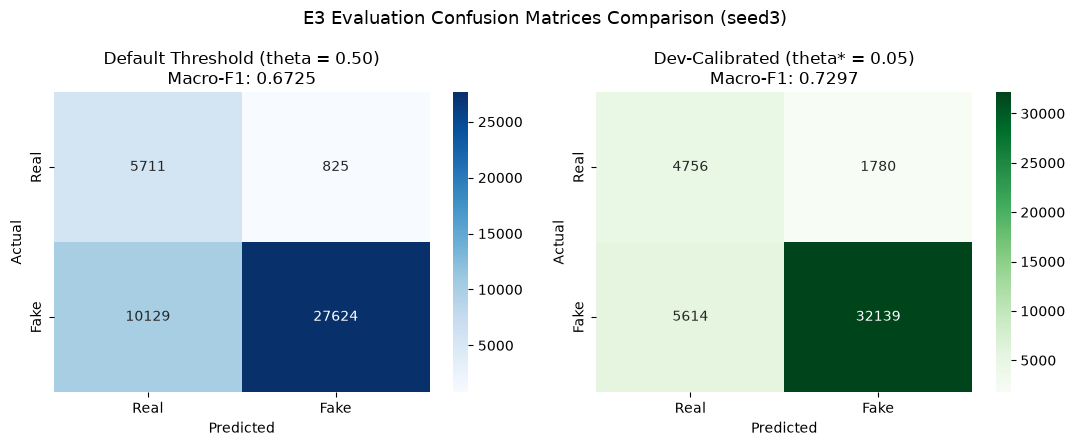

Saved dual confusion matrix figure to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/reworked/E3_conservative_finetune/E3_ATADD_eval_confusion_matrix_seed3.png


In [26]:
# 24.5. Dual-Threshold Generalization Analysis: Per-Type, Per-Generator, & Seen vs Unseen Real Sources

if len(eval_run_df) and len(eval_scores):
    eval_analysis = eval_run_df[
        [
            "file_id",
            "type",
            "label",
            "generator",
            "source"
        ]
    ].copy()

    eval_analysis["label_id"] = eval_analysis["label"].map(LABEL_MAP)
    eval_analysis["spoof_score"] = eval_scores
    eval_analysis["prediction_05"] = (eval_scores >= 0.5).astype(int)
    eval_analysis["prediction_opt"] = (eval_scores >= best_dev_thresh).astype(int)
    eval_analysis["prediction"] = eval_analysis["prediction_05"]

    print("======================================================================")
    print(f"DUAL-THRESHOLD GENERALIZATION AUDIT ({SEED_TAG})")
    print(f"Thresholds: Default theta=0.50  vs.  Dev-Calibrated theta*={best_dev_thresh:.4f}")
    print("======================================================================")

    # -------------------------------------------------------------------------
    # A. Per-Type Domain Breakdown at BOTH Thresholds
    # -------------------------------------------------------------------------
    print(f"\n[A] Per-Type Domain Breakdown (4 Domains)")
    print("-" * 70)
    type_results = []
    for audio_type in ["speech", "sound", "singing", "music"]:
        subset = eval_analysis[eval_analysis["type"] == audio_type]
        if len(subset) == 0:
            continue
        y_true = subset["label_id"].to_numpy()
        scores = subset["spoof_score"].to_numpy()
        if len(np.unique(y_true)) < 2:
            continue

        metrics_05, _ = calculate_metrics(y_true, scores, threshold=0.5)
        metrics_opt, _ = calculate_metrics(y_true, scores, threshold=best_dev_thresh)

        type_results.append({
            "Domain": audio_type.capitalize(),
            "Total Samples": len(subset),
            "Real Samples": int((y_true == 0).sum()),
            "Fake Samples": int((y_true == 1).sum()),
            "Macro-F1 (0.50)": metrics_05["macro_f1"],
            "Macro-F1 (theta*)": metrics_opt["macro_f1"],
            "Delta F1": metrics_opt["macro_f1"] - metrics_05["macro_f1"],
            "AUROC": metrics_05["auroc"],
            "EER (%)": metrics_05["eer"] * 100.0
        })

    type_results_df = pd.DataFrame(type_results, columns=[
        "Domain", "Total Samples", "Real Samples", "Fake Samples",
        "Macro-F1 (0.50)", "Macro-F1 (theta*)", "Delta F1", "AUROC", "EER (%)"
    ])
    display(type_results_df)

    type_avg_f1_05 = float(type_results_df["Macro-F1 (0.50)"].mean()) if len(type_results_df) else None
    type_avg_f1_opt = float(type_results_df["Macro-F1 (theta*)"].mean()) if len(type_results_df) else None
    if type_avg_f1_05 is not None and type_avg_f1_opt is not None:
        print(f"Type-Averaged Macro-F1 at theta=0.50   : {type_avg_f1_05:.6f}")
        print(f"Type-Averaged Macro-F1 at theta*={best_dev_thresh:.2f}: {type_avg_f1_opt:.6f} (Delta: {type_avg_f1_opt - type_avg_f1_05:+.6f})")
    else:
        print("No domain contained both classes; type-averaged Macro-F1 is unavailable.")

    type_results_path = EXPERIMENT_DIR / f"E3_ATADD_eval_type_results_{SEED_TAG}.csv"
    type_results_df.to_csv(type_results_path, index=False)
    table_path = RESULT_TABLE_DIR / f"E3_ATADD_eval_domain_summary_{SEED_TAG}.csv"
    type_results_df.to_csv(table_path, index=False)
    print("Saved domain breakdown to:", type_results_path)

    # -------------------------------------------------------------------------
    # B. Per-Generator Breakdown on Fake Samples at BOTH Thresholds
    # -------------------------------------------------------------------------
    print(f"\n[B] Per-Generator Breakdown on 38 Unseen Fake Generators")
    print("-" * 70)
    fake_eval = eval_analysis[eval_analysis["label"] == "fake"]
    generator_results = []

    for generator, group in fake_eval.groupby("generator"):
        if generator == "-" or pd.isna(generator):
            continue
        scores = group["spoof_score"].to_numpy()
        preds_05 = group["prediction_05"].to_numpy()
        preds_opt = group["prediction_opt"].to_numpy()

        det_05 = int((preds_05 == 1).sum())
        det_opt = int((preds_opt == 1).sum())
        total = len(group)

        generator_results.append({
            "Generator": generator,
            "Domain": group["type"].mode().iloc[0],
            "Samples": total,
            "Recall (0.50)": det_05 / total,
            "Recall (theta*)": det_opt / total,
            "Delta Recall": (det_opt - det_05) / total,
            "Mean Spoof Score": float(scores.mean())
        })

    generator_results_df = pd.DataFrame(generator_results, columns=[
        "Generator", "Domain", "Samples", "Recall (0.50)", "Recall (theta*)",
        "Delta Recall", "Mean Spoof Score"
    ])
    if len(generator_results_df):
        generator_results_df = generator_results_df.sort_values("Recall (theta*)")
    display(generator_results_df.head(15))
    print(f"Additional generators not shown: {max(0, len(generator_results_df) - 15)}")

    gen_path = EXPERIMENT_DIR / f"E3_ATADD_eval_generator_results_{SEED_TAG}.csv"
    generator_results_df.to_csv(gen_path, index=False)
    print("Saved generator breakdown to:", gen_path)

    # -------------------------------------------------------------------------
    # C. Real Audio: Seen vs. Unseen Real Source Breakdown at BOTH Thresholds
    # -------------------------------------------------------------------------
    print(f"\n[C] Real Audio: Seen vs. Unseen Source Breakdown")
    print("-" * 70)
    seen_sources = set(train_df.loc[train_df["label"] == "real", "source"]) | set(dev_df.loc[dev_df["label"] == "real", "source"])
    real_eval = eval_analysis[eval_analysis["label"] == "real"].copy()
    real_eval["source_category"] = real_eval["source"].apply(
        lambda s: "Seen Source" if s in seen_sources else "Unseen Source"
    )

    real_source_results = []
    for cat, group in real_eval.groupby("source_category"):
        total = len(group)
        correct_05 = int((group["prediction_05"] == 0).sum())
        fp_05 = int((group["prediction_05"] == 1).sum())

        correct_opt = int((group["prediction_opt"] == 0).sum())
        fp_opt = int((group["prediction_opt"] == 1).sum())

        real_source_results.append({
            "Source Category": cat,
            "Clips": total,
            "Real Acc (0.50)": f"{correct_05 / total * 100:.2f}%",
            "False Alarm (0.50)": f"{fp_05 / total * 100:.2f}%",
            "Real Acc (theta*)": f"{correct_opt / total * 100:.2f}%",
            "False Alarm (theta*)": f"{fp_opt / total * 100:.2f}%",
            "Mean Spoof Score": float(group["spoof_score"].mean())
        })

    real_source_df = pd.DataFrame(real_source_results)
    display(real_source_df)

    real_source_path = EXPERIMENT_DIR / f"eval_real_source_breakdown_{SEED_TAG}.csv"
    real_source_df.to_csv(real_source_path, index=False)
    print("Saved real source breakdown to:", real_source_path)

    # -------------------------------------------------------------------------
    # D. Side-by-Side Confusion Matrices
    # -------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    cm_05 = confusion_matrix(eval_labels, eval_analysis["prediction_05"].to_numpy())
    sns.heatmap(cm_05, annot=True, fmt="d", cmap="Blues", ax=axes[0],
                xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
    axes[0].set_title(f"Default Threshold (theta = 0.50)\nMacro-F1: {eval_metrics_05['macro_f1']:.4f}")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")

    cm_opt = confusion_matrix(eval_labels, eval_analysis["prediction_opt"].to_numpy())
    sns.heatmap(cm_opt, annot=True, fmt="d", cmap="Greens", ax=axes[1],
                xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
    axes[1].set_title(f"Dev-Calibrated (theta* = {best_dev_thresh:.2f})\nMacro-F1: {eval_metrics_opt['macro_f1']:.4f}")
    axes[1].set_xlabel("Predicted")
    axes[1].set_ylabel("Actual")

    plt.suptitle(f"E3 Evaluation Confusion Matrices Comparison ({SEED_TAG})", fontsize=13)
    plt.tight_layout()
    eval_cm_path = RESULT_FIGURE_DIR / f"E3_ATADD_eval_confusion_matrix_{SEED_TAG}.png"
    plt.savefig(eval_cm_path, dpi=200)
    plt.show()
    print("Saved dual confusion matrix figure to:", eval_cm_path)
else:
    print("Evaluation analysis is not available.")


In [27]:
# Evaluation failure-case analysis (at both thresholds)

if len(eval_analysis):
    for thresh_tag, col in [("0.50", "prediction_05"), ("calibrated", "prediction_opt")]:
        fn = eval_analysis[
            (eval_analysis["label"].isin(["fake", "spoof"])) &
            (eval_analysis[col] == 0)
        ].copy()
        fp = eval_analysis[
            (eval_analysis["label"].isin(["real", "bonafide"])) &
            (eval_analysis[col] == 1)
        ].copy()

        print(f"Threshold [{thresh_tag}]: False Negatives (Missed Spoofs) = {len(fn):,}, False Positives (False Alarms) = {len(fp):,}")

        failures = pd.concat([
            fn.assign(error_type="false_negative", eval_threshold=thresh_tag),
            fp.assign(error_type="false_positive", eval_threshold=thresh_tag)
        ])

        fail_path = EXPERIMENT_DIR / f"E3_ATADD_eval_failure_cases_{thresh_tag}_{SEED_TAG}.csv"
        failures.to_csv(fail_path, index=False)
        print(f"Saved {thresh_tag} failure cases to: {fail_path}")

    # Backward compatibility file
    default_failures = eval_analysis[
        ((eval_analysis["label"].isin(["fake", "spoof"])) & (eval_analysis["prediction_05"] == 0)) |
        ((eval_analysis["label"].isin(["real", "bonafide"])) & (eval_analysis["prediction_05"] == 1))
    ]
    compat_path = EXPERIMENT_DIR / f"E3_ATADD_eval_failure_cases_{SEED_TAG}.csv"
    default_failures.to_csv(compat_path, index=False)
    print("Saved default failure cases to:", compat_path)
else:
    print("Evaluation analysis is not available.")


Threshold [0.50]: False Negatives (Missed Spoofs) = 10,129, False Positives (False Alarms) = 825
Saved 0.50 failure cases to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune/E3_ATADD_eval_failure_cases_0.50_seed3.csv
Threshold [calibrated]: False Negatives (Missed Spoofs) = 5,614, False Positives (False Alarms) = 1,780
Saved calibrated failure cases to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune/E3_ATADD_eval_failure_cases_calibrated_seed3.csv
Saved default failure cases to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune/E3_ATADD_eval_failure_cases_seed3.csv


### Evaluation analysis note

The generator/type/source breakdown is reported only for metadata present in the frozen evaluation manifest. No claim is made that unknown or placeholder speaker identities are disjoint. The primary generator generalization claim is supported by the explicit known-generator overlap audit performed before training.


# 25. Save the E3 experiment configuration

The final configuration records the model, preprocessing, dataset preparation version and training settings.

This is important because later changes to preprocessing or model design should produce a new experiment version rather than silently changing the meaning of E3.


In [28]:
# 25. Save the complete E3 Reworked AT-ADD configuration

config = {
    "experiment": f"E3_ATADD_Reworked_{SEED_TAG}",
    "seed_tag": SEED_TAG,
    "seed": SEED,
    "experiment_version": EXPERIMENT_VERSION,
    "model_family": "PANNs_MobileNetV2_AudioSet_Pretrained_Adapted80Mel",
    "preprocessing_module": "src/preprocessing/preprocess_atadd_rerun.py",
    "dataset_preparation_version": "AT-ADD_reworked_v1",
    "model": {
        "name": "PANNs-MobileNetV2-AudioSet",
        "weights": "AudioSet_pretrained",
        "pretrained_weights_path": str(PRETRAINED_WEIGHTS_PATH),
        "input_channels": 1,
        "num_classes": 2,
        "classifier_dropout": CLASSIFIER_DROPOUT,
        "input_layout": "B,1,time,mel",
        "pooling": "mean over mel-frequency axis, followed by temporal max + temporal mean",
        "bn0": "fresh BatchNorm2d(80); original checkpoint bn0 has 64 mel bins",
        "pretrained_load_report": model.pretrained_load_report,
        "total_parameters": total_params,
        "trainable_parameters": trainable_params
    },
    "audio": {
        "sampling_rate": SAMPLE_RATE,
        "segment_seconds": SEGMENT_SECONDS,
        "num_samples": NUM_SAMPLES,
        "padding_mode": "circular_repeat",
        "n_fft": N_FFT,
        "win_length": WIN_LENGTH,
        "hop_length": HOP_LENGTH,
        "n_mels": N_MELS,
        "mel_mean": float(MEL_MEAN),
        "mel_std": float(MEL_STD)
    },
    "threshold_calibration": {
        "method": "maximize development Macro-F1",
        "grid_start": 0.01,
        "grid_stop": 0.99,
        "grid_points": 99,
        "grid_matches_E1_E2": True,
        "primary_fixed_threshold": 0.5
    },
    "training": {
        "batch_size": BATCH_SIZE,
        "epochs_budget": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "learning_rates": {
            "pretrained_features": BACKBONE_LEARNING_RATE,
            "pretrained_fc1": FC1_LEARNING_RATE,
            "fresh_bn0": LEARNING_RATE,
            "binary_classifier": LEARNING_RATE
        },
        "freeze_pretrained_bn_running_stats": FREEZE_PRETRAINED_BN_STATS,
        "weight_decay": WEIGHT_DECAY,
        "max_grad_norm": MAX_GRAD_NORM,
        "loss": "class_weighted_cross_entropy",
        "class_weights": {
            "real": float(class_weights[0]),
            "fake": float(class_weights[1])
        },
        "scheduler": "ReduceLROnPlateau(mode=max, factor=0.5, patience=3, min_lr=1e-6)"
    },
    "dataset_splits": {
        "manifest_directory": str(MANIFEST_DIR),
        "train_samples": len(train_df),
        "dev_samples": len(dev_df),
        "eval_samples": len(eval_df),
        "train_run_samples": len(train_run_df),
        "dev_run_samples": len(dev_run_df),
        "eval_run_samples": len(eval_run_df),
        "train_fraction": TRAIN_FRACTION,
        "dev_fraction": DEV_FRACTION,
        "eval_fraction": EVAL_FRACTION,
        "train_manifest_fingerprint": TRAIN_MANIFEST_FINGERPRINT
    },
    "results": {
        "best_dev_macro_f1": float(best_dev_f1),
        "best_epoch": int(best_epoch),
        "optimal_dev_threshold": float(best_dev_thresh),
        "eval_macro_f1_05": float(eval_metrics_05["macro_f1"]),
        "eval_macro_f1_opt": float(eval_metrics_opt["macro_f1"]),
        "eval_type_avg_f1_05": type_avg_f1_05,
        "eval_type_avg_f1_opt": type_avg_f1_opt
    }
}

config_path = EXPERIMENT_DIR / f"E3_ATADD_config_{SEED_TAG}.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print(f"Saved complete E3 Reworked configuration to: {config_path}")


Saved complete E3 Reworked configuration to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/reworked/E3_conservative_finetune/E3_ATADD_config_seed3.json


# E3 PANNs MobileNetV2 AT-ADD experiment record

## Model
The convolutional feature extractor and 1280→1024 `fc1` embedding are initialized from the PANNs MobileNetV2 AudioSet checkpoint. The original AudioSet classifier is replaced with a new 1024→2 binary head. Pooling follows the PANNs order: mean over the mel-frequency axis, then temporal max plus temporal mean. The 80-bin `bn0` is newly initialized because the upstream checkpoint uses 64 mel bins.

## Dataset
The frozen Reworked train/dev/eval manifests are used without rewriting split assignments. Pairwise overlap checks operate on known non-placeholder fake-generator IDs, real-audio speaker IDs, and source IDs where present; missing identity metadata is reported separately.

## Acoustic input
E3 uses the same 24 kHz, mono, 4-second repeat-pad and 80-bin log-Mel values as E1/E2, transposing their layout to `[B, 1, time, mel]` before the pretrained PANNs model.

## Experimental boundary
This is the pretrained audio transfer baseline before robustness transformations or edge compression. Since the frontend and `bn0` are adapted for 80 bins, it is a PANNs-initialized transfer baseline, not a claim of bit-for-bit reproduction of the original AudioSet tagging setup.

## Fine-tuning stabilization
The pretrained convolutional feature stack uses a lower learning rate than the new 80-bin normalization layer and binary classifier. Running means/variances in pretrained feature BatchNorm layers remain fixed during training to reduce drift under the adapted 24 kHz / 80-bin frontend. Compare the saved fixed-threshold Macro-F1 with AUROC/EER because a fixed-threshold drop can reflect score calibration drift as well as representation changes.


# 26. E3 outputs and experiment record

After a successful run, E3 should leave behind four kinds of evidence:

1. **Configuration** - exactly how E3 was run.
2. **Checkpoint** - the selected PANNs MobileNetV2 model.
3. **Quantitative results** - Macro-F1, AUROC, EER and related metrics.
4. **Analysis artifacts** - predictions, training curves and confusion matrix.

These artifacts provide the record needed to compare E3 with E1 and E2.


In [29]:
# E3 experiment artifact audit

required_artifacts = {
    "Best checkpoint": CHECKPOINT_DIR / f"E3_PANNs_MobileNetV2_ATADD_best_{SEED_TAG}.pt",
    "Log-Mel normalization statistics": EXPERIMENT_DIR / f"E3_ATADD_logmel_stats_{SEED_TAG}.json",
    "Training history": EXPERIMENT_DIR / f"E3_ATADD_training_history_{SEED_TAG}.csv",
    "Validation metrics": EXPERIMENT_DIR / f"E3_ATADD_validation_metrics_{SEED_TAG}.json",
    "Validation predictions": EXPERIMENT_DIR / f"E3_ATADD_val_predictions_{SEED_TAG}.csv",
    "Evaluation predictions": EXPERIMENT_DIR / f"E3_ATADD_eval_predictions_{SEED_TAG}.csv",
    "Evaluation metrics": EXPERIMENT_DIR / f"E3_ATADD_eval_metrics_{SEED_TAG}.json",
    "AT-ADD type results": EXPERIMENT_DIR / f"E3_ATADD_eval_type_results_{SEED_TAG}.csv",
    "AT-ADD generator results": EXPERIMENT_DIR / f"E3_ATADD_eval_generator_results_{SEED_TAG}.csv",
    "Real source breakdown": EXPERIMENT_DIR / f"eval_real_source_breakdown_{SEED_TAG}.csv",
    "Failure-case results": EXPERIMENT_DIR / f"E3_ATADD_eval_failure_cases_{SEED_TAG}.csv",
    "Evaluation confusion matrix": RESULT_FIGURE_DIR / f"E3_ATADD_eval_confusion_matrix_{SEED_TAG}.png",
    "Validation confusion matrix": RESULT_FIGURE_DIR / f"E3_ATADD_validation_confusion_matrix_{SEED_TAG}.png",
    "Training curves figure": RESULT_FIGURE_DIR / f"E3_ATADD_training_curves_{SEED_TAG}.png",
    "Domain summary table": RESULT_TABLE_DIR / f"E3_ATADD_eval_domain_summary_{SEED_TAG}.csv",
    "Experiment configuration": EXPERIMENT_DIR / f"E3_ATADD_config_{SEED_TAG}.json"
}

print(f"E3 AT-ADD Reworked Experiment Artifact Audit ({SEED_TAG})")
print("-" * 65)
all_available = True
for name, path in required_artifacts.items():
    status = "OK" if path.exists() else "PENDING EXECUTION"
    print(f"{name:<35}: {status}")
    if not path.exists():
        all_available = False
print("-" * 65)
if all_available:
    print(f"All required E3 artifacts for {SEED_TAG} are available.")
else:
    print(f"Pending artifacts will be generated upon executing the {SEED_TAG} training run.")


E3 AT-ADD Reworked Experiment Artifact Audit (seed3)
-----------------------------------------------------------------
Best checkpoint                    : OK
Log-Mel normalization statistics   : OK
Training history                   : OK
Validation metrics                 : OK
Validation predictions             : OK
Evaluation predictions             : OK
Evaluation metrics                 : OK
AT-ADD type results                : OK
AT-ADD generator results           : OK
Real source breakdown              : OK
Failure-case results               : OK
Evaluation confusion matrix        : OK
Validation confusion matrix        : OK
Training curves figure             : OK
Domain summary table               : OK
Experiment configuration           : OK
-----------------------------------------------------------------
All required E3 artifacts for seed3 are available.
